# E. coli Core FluxTransformer Evaluation

Evaluate a pretrained FluxTransformer using signed pFBA-simulated *E. coli* core data: inputs are signed exchange lower bounds (negative for enabled uptake), and targets are signed reaction fluxes. Inspect whether its flux predictions and learned token embeddings preserve useful metabolic structure.

Main workflow: load and sanity-check the checkpoint/test data, inspect training loss and flux diagnostics, compute pooled and per-flux metrics, audit difficult fluxes, and visualize token embeddings with t-SNE/UMAP using pathway, correlation, stoichiometric, and selected-subset views.

In [1]:
import os
from datetime import date

import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
from openTSNE import TSNEEmbedding, affinity, initialization

from ecoli_core_merged_transformer import load_data, prepare_tensors, set_seed

%matplotlib inline
pd.set_option('display.max_rows', None)

DATA_PATH = None

In [2]:
class AttentionBlock(nn.Module):
    """Multi-head attention block with per-head diffusion of c."""
    def __init__(self, d_model=128, n_heads=8, dropout=0.05):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"

        self.d_model = d_model
        self.n_heads = n_heads

        self.layer_norm = nn.LayerNorm(d_model)

        self.mha = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True,
        )

        # Learnable head aggregation
        self.head_scores = nn.Parameter(torch.zeros(n_heads))

    def forward(self, x, c):
        """
        x: (B, S, d_model)
        c: (B, S, 1)
        returns: x_out (B, S, d_model), c_out (B, S, 1)
        """
        x_norm = self.layer_norm(x)

        # Get per-head attention weights: (B, H, S, S)
        attn_out, attn_weights = self.mha(
            x_norm, x_norm, x_norm,
            need_weights=True,
            average_attn_weights=False
        )
        
        x_out = attn_out + x

        # Per-head diffusion of c:
        # (B, H, S, S) @ (B, 1, S, 1) -> (B, H, S, 1)
        c_heads = torch.matmul(attn_weights, c.unsqueeze(1))
        alpha = F.softmax(self.head_scores, dim=0).view(1, self.n_heads, 1, 1)  # (1,H,1,1)
        c_att = (c_heads * alpha).sum(dim=1)  # (B, S, 1)

        c_out = c_att + c

        return x_out, c_out


In [3]:
class FeedForwardBlock(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.05):
        super().__init__()

        self.d_model = d_model + 1
        self.d_ff = d_ff

        self.layer_norm = nn.LayerNorm(self.d_model)
        self.linear1 = nn.Linear(self.d_model, self.d_ff)
        self.activation = nn.GELU()
        self.linear2 = nn.Linear(self.d_ff, self.d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, c):
        y = torch.cat((x, c), dim=2)
        
        norm_y = self.layer_norm(y)
        hidden = self.linear1(norm_y)
        hidden = self.activation(hidden)
        hidden = self.dropout(hidden)
        output = self.linear2(hidden)

        return output + y

In [4]:
class FluxTransformerLayer(nn.Module):
    """Single transformer block without embedding layer"""
    def __init__(self, d_model=128, n_heads=8, d_ff=1024, dropout=0.05):
        super().__init__()
        self.d_model = d_model
        
        self.attention_block = AttentionBlock(d_model, n_heads, dropout)
        self.feedforward_block = FeedForwardBlock(d_model, d_ff, dropout)
        
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
    
    def forward(self, x, c):
        attn_x, attn_c = self.attention_block(x, c)
        ff_output = self.feedforward_block(attn_x, attn_c)
        
        # Split the concatenated output
        updated_x = ff_output[:, :, :-1]
        updated_c = ff_output[:, :, -1:]
        
        return updated_x, updated_c
        
class FluxTransformer(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        input_token_indices,          # list[int] or 1D tensor[int64]
        d_model=128,
        n_heads=8,
        n_layers=3,
        d_ff=1024,
        dropout=0.05,
    ):
        super().__init__()
        if vocab_size is None:
            raise ValueError("vocab_size must be provided explicitly.")
        self.vocab_size = int(vocab_size)
        self.d_model = d_model

        idx = torch.as_tensor(input_token_indices, dtype=torch.long)
        if idx.ndim != 1:
            raise ValueError("input_token_indices must be 1D.")
        if (idx < 0).any() or (idx >= self.vocab_size).any():
            raise ValueError("input_token_indices contains out-of-range indices.")
        # Register as buffer so it moves with .to(device)
        self.register_buffer("input_token_indices", idx, persistent=True)

        self.input_embedding = nn.Embedding(self.vocab_size, d_model)

        self.layers = nn.ModuleList([
            FluxTransformerLayer(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=dropout)
            for _ in range(n_layers)
        ])

    def forward(self, c, output_subset=None, return_embedding=False):
        """
        c: (batch, vocab_size, 1)
        output_subset: 1D tensor of token indices to train on (typically excludes injected tokens)
        """
        batch_size = c.size(0)

        always = self.input_token_indices  # (n_injected,)

        if output_subset is None:
            selected_indices = torch.arange(self.vocab_size, device=c.device)
        else:
            output_subset = output_subset.to(c.device).long()
            selected_indices = torch.unique(torch.cat([always, output_subset]), sorted=True)

        y = selected_indices.unsqueeze(0).expand(batch_size, -1)      # (B, S)
        x = self.input_embedding(y)                                    # (B, S, d_model)

        c_subset = c[:, selected_indices, :]                           # (B, S, 1)
        c_subset_all_layers = torch.zeros(batch_size, c_subset.size(1), len(self.layers), device=c.device)

        for e, layer in enumerate(self.layers):
            x, c_subset = layer(x, c_subset)
            c_subset_all_layers[:, :, e] = c_subset.squeeze(-1)

        if return_embedding:
            return x, selected_indices

        return c_subset_all_layers, selected_indices


In [5]:
def load_pretrained_model(checkpoint_path, device=None):
    """
    Load a pretrained model from a checkpoint file (*_checkpoint.pth).

    Returns:
        model: FluxTransformer on `device`, in eval() mode
        config: dict
        train_losses: list[float]
        test_losses: list[float]
        data_info: dict
    """
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"

    ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
    #ckpt = torch.load(checkpoint_path, map_location=device)

    # Basic validation
    required_top = ["model_state_dict", "config", "train_losses", "test_losses", "data_info"]
    missing_top = [k for k in required_top if k not in ckpt]
    if missing_top:
        raise KeyError(f"Checkpoint missing keys: {missing_top}. Got keys: {list(ckpt.keys())}")

    config = ckpt["config"]

    input_token_indices = config.get("input_token_indices", None)

    if input_token_indices is None:
        raise KeyError(
            "Checkpoint is missing 'input_token_indices' in config/data_info. "
            "Cannot reconstruct FluxTransformer."
        )

    vocab_size = config.get("vocab_size", None)

    # Build model
    model = FluxTransformer(
        vocab_size=int(vocab_size),
        input_token_indices=input_token_indices,
        d_model=int(config["d_model"]),
        n_heads=int(config["n_heads"]),
        n_layers=int(config["n_layers"]),
        d_ff=int(config["d_ff"]),
        dropout=float(config["dropout"]),
    ).to(device)

    # Load weights
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    train_losses = ckpt["train_losses"]
    test_losses = ckpt["test_losses"]
    data_info = ckpt["data_info"]

    print(f"Loaded checkpoint: {checkpoint_path}")
    print(
        f"vocab_size={vocab_size}, n_injected={len(input_token_indices)}, "
        f"d_model={config['d_model']}, n_heads={config['n_heads']}, "
        f"n_layers={config['n_layers']}, d_ff={config['d_ff']}"
    )

    return model, config, train_losses, test_losses, data_info

### Plotting Functions

In [6]:
def plot_loss_curves(train_losses, test_losses, d_model, n_heads, n_layers, d_ff, save_path=None, log_scale=True):
    epochs = np.arange(1, len(train_losses) + 1)
    plt.figure(figsize=(14, 10))
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.plot(epochs, train_losses, label="Training Loss")
    plt.plot(epochs, test_losses, label="Test Loss")
    if log_scale:
        plt.yscale('log')
    plt.xlabel("Epoch", fontsize=18)
    plt.ylabel("Loss", fontsize=18)
    plt.title(f"Loss Curves (d={d_model}, h={n_heads}, l={n_layers}, ff={d_ff})", fontsize=20)
    plt.grid(True)
    plt.legend(fontsize=16)
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path)
        plt.close()
        print(f"\nTraining curve saved to {save_path}")
    else:
        plt.show()

In [7]:
def plot_diagnostics_2x2(y_true, y_pred, label, save_path=None, show=True):
    """Creates a 2x2 matrix of plots: true vs predicted, residuals, error distribution, and histogram of samples."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    residuals = y_true - y_pred
    display_label = label[:-5] if str(label).endswith('_flux') else label
    max_abs_error = float(np.nanmax(np.abs(residuals))) if residuals.size else 1.0
    if not np.isfinite(max_abs_error) or max_abs_error == 0.0:
        max_abs_error = 1.0

    title_fs = 15
    label_fs = 13
    tick_fs = 11

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    # True vs Predicted
    axs[0, 0].scatter(y_true, y_pred, alpha=0.2, s=5, color='royalblue')
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    axs[0, 0].plot([lo, hi], [lo, hi], 'k--', lw=2)
    axs[0, 0].set_title(f'True vs Predicted: {display_label}', fontsize=title_fs)
    axs[0, 0].set_xlabel('True value', fontsize=label_fs)
    axs[0, 0].set_ylabel('Predicted', fontsize=label_fs)
    axs[0, 0].grid(True)

    # Residuals plot
    axs[0, 1].scatter(y_true, residuals, alpha=0.15, color='darkorange')
    axs[0, 1].axhline(y=0, color='r', linestyle='-')
    axs[0, 1].set_ylim(-max_abs_error, max_abs_error)
    axs[0, 1].set_title(f'Residuals: {display_label}', fontsize=title_fs)
    axs[0, 1].set_xlabel('True value', fontsize=label_fs)
    axs[0, 1].set_ylabel('Residuals', fontsize=label_fs)
    axs[0, 1].grid(True)

    # Error distribution
    sns.histplot(residuals, kde=True, stat='density', ax=axs[1, 0], legend=False, color='indianred')
    axs[1, 0].set_xlim(-max_abs_error, max_abs_error)
    axs[1, 0].set_title(f'Prediction Error Distribution: {display_label}', fontsize=title_fs)
    axs[1, 0].set_xlabel('Prediction Error', fontsize=label_fs)
    axs[1, 0].set_ylabel('Density', fontsize=label_fs)
    axs[1, 0].grid(True)

    # Histogram of actual values
    sns.histplot(y_true, kde=True, stat='density', bins=100, ax=axs[1, 1], legend=False, color='mediumseagreen')
    axs[1, 1].set_title(f'True Value Distribution: {display_label}', fontsize=title_fs)
    axs[1, 1].set_xlabel('True Value', fontsize=label_fs)
    axs[1, 1].set_ylabel('Density', fontsize=label_fs)
    axs[1, 1].grid(True)

    for ax in axs.ravel():
        ax.tick_params(labelsize=tick_fs)

    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
    if show:
        plt.show()
    plt.close(fig)

In [8]:
def plot_flux(
    model,
    X_test,
    y_test,
    outputs,
    flux_name: str,
    save_path=None,
):
    """
    Plot diagnostics for a token name in `outputs`.

    Assumptions:
      - outputs defines token order, len(outputs) == model.vocab_size
      - X_test is (N, vocab_size) and contains medium constraints only at injected token indices
      - y_test is (N, vocab_size) and contains realized fluxes for all tokens
      - model forward returns (preds_all_layers, selected_indices)
        where preds_all_layers is (N, S, n_layers) and selected_indices are token indices

    This plots the realized flux target vs predicted realized flux for the requested token slot.
    """
    model_cpu = model.to("cpu").eval()

    # Basic sanity checks
    if len(outputs) != getattr(model_cpu, "vocab_size", None):
        raise ValueError(f"len(outputs)={len(outputs)} does not match model.vocab_size={model_cpu.vocab_size}")

    if X_test.ndim != 2 or y_test.ndim != 2:
        raise ValueError(f"Expected X_test and y_test as 2D tensors (N, vocab_size). Got {X_test.shape=}, {y_test.shape=}")

    if X_test.shape[1] != model_cpu.vocab_size or y_test.shape[1] != model_cpu.vocab_size:
        raise ValueError(
            f"Feature dim mismatch. Expected vocab_size={model_cpu.vocab_size}. "
            f"Got X_test.shape[1]={X_test.shape[1]}, y_test.shape[1]={y_test.shape[1]}"
        )

    if flux_name not in outputs:
        raise ValueError(f"Flux '{flux_name}' not in outputs (len={len(outputs)}).")

    token_idx = outputs.index(flux_name)

    with torch.no_grad():
        preds_all_layers, selected_indices = model_cpu(
            X_test.unsqueeze(-1).to("cpu"),
            output_subset=None
        )

    # Map token_idx -> its position inside selected_indices (should exist when output_subset=None)
    selected_indices_np = selected_indices.cpu().numpy()
    pos = np.where(selected_indices_np == token_idx)[0]
    if pos.size == 0:
        raise RuntimeError(
            f"Token index {token_idx} for '{flux_name}' was not produced by the model forward pass. "
            "This should not happen when output_subset=None."
        )
    pos = int(pos[0])

    # last-layer scalar prediction for this token: (N,)
    y_pred = preds_all_layers[:, pos, -1].cpu().numpy()
    y_true = y_test[:, token_idx].cpu().numpy()

    # Is this an injected (medium constraint) token slot?
    injected = False
    if hasattr(model_cpu, "input_token_indices") and model_cpu.input_token_indices is not None:
        injected = bool((model_cpu.input_token_indices.cpu() == token_idx).any().item())

    print(f"{flux_name} token index: {token_idx}")
    print(f"injected medium slot: {injected}")
    print("y_true range:", float(y_true.min()), "to", float(y_true.max()))
    print("y_pred range:", float(y_pred.min()), "to", float(y_pred.max()))

    plot_diagnostics_2x2(
        y_true=y_true,
        y_pred=y_pred,
        label=flux_name,
        save_path=save_path,
        show=True
    )

In [9]:
def plot_post_attention_real_context(
    model,
    token_names,                 # full token list, len == model.vocab_size
    X_test,                      # (N, vocab_size) token matrix (your injected-medium X_tok)
    *,
    token_indices=None,          # optional list[int] of token indices to visualize
    method="pca",
    n_components=2,
    n_samples=1000,
    perplexity=30.0,
    n_neighbors=15,
    min_dist=0.1,
    save_path=None,
    batch_size=128,
    random_state=42,
):
    device = next(model.parameters()).device
    model.eval()

    V = model.vocab_size
    if len(token_names) != V:
        raise ValueError(f"token_names length {len(token_names)} must equal model.vocab_size {V}.")

    # X_test must be (N, V)
    if not torch.is_tensor(X_test):
        X_test = torch.tensor(X_test, dtype=torch.float32)
    if X_test.dim() != 2 or X_test.size(1) != V:
        raise ValueError(f"X_test must have shape (N, {V}). Got {tuple(X_test.shape)}")

    N = min(int(n_samples), int(X_test.size(0)))

    if token_indices is None:
        token_indices = list(range(V))
    else:
        token_indices = [int(i) for i in token_indices]
        bad = [i for i in token_indices if i < 0 or i >= V]
        if bad:
            raise ValueError(f"token_indices contains out-of-range indices: {bad[:10]}")

    n_tok = len(token_indices)
    if n_tok == 0:
        raise ValueError("No tokens selected to plot (token_indices is empty).")

    all_embeddings = []
    token_id_labels = []

    with torch.no_grad():
        for i in range(0, N, batch_size):
            bs = min(batch_size, N - i)
            batch_context = X_test[i:i+bs].to(device).unsqueeze(-1)  # (B, V, 1)

            # return_embedding=True returns (x, selected_indices)
            x, _ = model(batch_context, output_subset=None, return_embedding=True)
            # x: (B, V, d_model)

            tok_x = x[:, token_indices, :]  # (B, n_tok, d_model)
            all_embeddings.append(tok_x.cpu())
            token_id_labels.append(np.tile(np.arange(n_tok), bs))

    all_embeddings = torch.cat(all_embeddings, dim=0)               # (N, n_tok, d_model)
    token_id_labels = np.concatenate(token_id_labels)              # (N*n_tok,)
    embeddings_flat = all_embeddings.reshape(-1, all_embeddings.shape[-1]).numpy()

    # Dimensionality reduction
    m = method.lower()
    if m == "pca":
        reducer = PCA(n_components=n_components)
        method_name = "PCA"
    elif m == "tsne":
        reducer = TSNE(
            n_components=n_components,
            perplexity=perplexity,
            random_state=random_state,
            init="pca",
        )
        method_name = "t-SNE"
    elif m == "umap":
        try:
            from umap import UMAP
        except ImportError as e:
            raise ImportError("UMAP not installed. Install with: pip install umap-learn") from e
        reducer = UMAP(
            n_components=n_components,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            random_state=random_state,
        )
        method_name = "UMAP"
    else:
        raise ValueError(f"Invalid method '{method}'. Use 'pca', 'tsne', or 'umap'.")

    embeddings_rd = reducer.fit_transform(embeddings_flat)

    # Colormap + per-token center (median)
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, n_tok))
    discrete_cmap = ListedColormap(colors)

    centers = []
    for local_idx in range(n_tok):
        mask = (token_id_labels == local_idx)
        if np.any(mask):
            centers.append((local_idx, np.median(embeddings_rd[mask], axis=0)))

    # Plot
    if n_components == 3:
        import mpl_toolkits.mplot3d  # noqa: F401
        fig = plt.figure(figsize=(16, 12))
        ax = fig.add_subplot(111, projection="3d")
        ax.scatter(
            embeddings_rd[:, 0], embeddings_rd[:, 1], embeddings_rd[:, 2],
            c=token_id_labels, cmap=discrete_cmap, alpha=0.15, s=7, edgecolors="none"
        )
        ax.set_title(f"Post-Attention Embeddings\n({N} contexts, {method_name})", fontsize=20)
        ax.set_xlabel(f"{method_name} 1", fontsize=16)
        ax.set_ylabel(f"{method_name} 2", fontsize=16)
        ax.set_zlabel(f"{method_name} 3", fontsize=16)
        ax.tick_params(labelsize=15)
        ax.grid(alpha=0.2)

    elif n_components == 2:
        plt.figure(figsize=(16, 12))
        plt.scatter(
            embeddings_rd[:, 0], embeddings_rd[:, 1],
            c=token_id_labels, cmap=discrete_cmap, alpha=0.2, s=10, edgecolors="none"
        )

        for local_idx, center in centers:
            global_idx = token_indices[local_idx]
            name = token_names[global_idx].replace("_flux", "")
            plt.scatter(
                center[0], center[1],
                s=30, marker="o",
                color=colors[local_idx],
                edgecolor="black", linewidth=0.5
            )
            plt.annotate(
                name, center,
                xytext=(5, 5), textcoords="offset points",
                fontsize=11,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8)
            )

        plt.title(f"Post-Attention Embeddings\n({N} contexts, {method_name})", fontsize=26)
        plt.xlabel(f"{method_name} 1", fontsize=22)
        plt.ylabel(f"{method_name} 2", fontsize=22)
        plt.xticks(fontsize=18)
        plt.yticks(fontsize=18)
        plt.grid(alpha=0.1)

    else:
        raise ValueError("n_components must be 2 or 3")

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Plot saved to {save_path}")
    plt.show()
    plt.close()

def plot_post_attn_tsne_gray(
    model,
    token_names,                 # full token list, len == model.vocab_size
    X_test,                      # (N, vocab_size) token matrix
    *,
    token_indices=None,          # optional list[int] of token indices to visualize
    n_samples=1000,
    perplexity=30.0,
    save_path=None,
    batch_size=128,
    random_state=42,
    annotate=False,
    annotate_fontsize=11,
    highlight_diverse_samples=False,
    n_diverse_samples=5,
    sample_color_mode="gray",    # "gray", "rainbow", "viridis", "plasma", or "coolwarm"
    show_pre_embeddings=False,
    show_pre_embedding_links=False,
):
    """
    Post-attention embedding plot fixed to:
      - t-SNE only
      - 2D only
      - gray mode (all points in gray) or colormap mode (per-sample colors)
      - optional pre-token embedding points included in the SAME t-SNE projection

    annotate=True labels token centers (median per token id).
    In gray mode, can highlight n_diverse_samples contexts in bright colors.
    In colormap modes, samples are colored by condition-similarity order
    (similar nutrient contexts get nearby colors), and highlighting is disabled.
    When show_pre_embeddings=True, pre-token points share the same t-SNE fit
    as the gray post-layer points, so their 2D positions show local relation
    to the plotted gray clusters.
    """
    device = next(model.parameters()).device
    model.eval()

    V = model.vocab_size
    if len(token_names) != V:
        raise ValueError(f"token_names length {len(token_names)} must equal model.vocab_size {V}.")

    if not torch.is_tensor(X_test):
        X_test = torch.tensor(X_test, dtype=torch.float32)
    if X_test.dim() != 2 or X_test.size(1) != V:
        raise ValueError(f"X_test must have shape (N, {V}). Got {tuple(X_test.shape)}")

    N = min(int(n_samples), int(X_test.size(0)))

    if token_indices is None:
        token_indices = list(range(V))
    else:
        token_indices = [int(i) for i in token_indices]
        bad = [i for i in token_indices if i < 0 or i >= V]
        if bad:
            raise ValueError(f"token_indices contains out-of-range indices: {bad[:10]}")

    n_tok = len(token_indices)
    if n_tok == 0:
        raise ValueError("No tokens selected to plot (token_indices is empty).")

    mode = str(sample_color_mode).strip().lower()
    allowed_modes = {"gray", "rainbow", "viridis", "plasma", "coolwarm"}
    if mode not in allowed_modes:
        raise ValueError("sample_color_mode must be one of: gray, rainbow, viridis, plasma, coolwarm.")
    use_colormap = (mode != "gray")
    use_highlight = bool(highlight_diverse_samples) and (not use_colormap)

    all_embeddings = []
    token_id_labels = []
    sample_id_labels = []

    # prepare normalized nutrient-condition vectors (for highlighting and colormap ordering)
    diverse_local_idx = np.array([], dtype=np.int64)
    X_norm_cond = None
    if (use_highlight or use_colormap) and N > 0:
        X_cond = X_test[:N]
        if torch.is_tensor(X_cond):
            X_cond = X_cond.detach().cpu().numpy()
        else:
            X_cond = np.asarray(X_cond, dtype=np.float32)

        if hasattr(model, "input_token_indices") and model.input_token_indices is not None:
            cond_idx = model.input_token_indices.detach().cpu().numpy().astype(np.int64)
            cond_idx = cond_idx[(cond_idx >= 0) & (cond_idx < X_cond.shape[1])]
            if cond_idx.size > 0:
                X_cond = X_cond[:, cond_idx]

        X_cond = X_cond.astype(np.float64, copy=False)
        mu = np.nanmean(X_cond, axis=0, keepdims=True)
        sigma = np.nanstd(X_cond, axis=0, keepdims=True)
        sigma[sigma < 1e-12] = 1.0
        X_norm_cond = (X_cond - mu) / sigma
        X_norm_cond = np.nan_to_num(X_norm_cond, nan=0.0, posinf=0.0, neginf=0.0)

    k_diverse = max(0, int(n_diverse_samples))
    if use_highlight and X_norm_cond is not None and k_diverse > 0:
        k_diverse = min(k_diverse, N)
        first = int(np.argmax(np.sum((X_norm_cond - X_norm_cond.mean(axis=0, keepdims=True)) ** 2, axis=1)))
        selected = [first]
        min_dist = np.full(N, np.inf, dtype=np.float64)
        for _ in range(1, k_diverse):
            d = np.sum((X_norm_cond - X_norm_cond[selected[-1]]) ** 2, axis=1)
            min_dist = np.minimum(min_dist, d)
            min_dist[selected] = -1.0
            selected.append(int(np.argmax(min_dist)))
        diverse_local_idx = np.array(selected, dtype=np.int64)

    with torch.no_grad():
        for i in range(0, N, batch_size):
            bs = min(batch_size, N - i)
            batch_context = X_test[i:i+bs].to(device).unsqueeze(-1)  # (B, V, 1)

            x, _ = model(batch_context, output_subset=None, return_embedding=True)
            tok_x = x[:, token_indices, :]  # (B, n_tok, d_model)
            all_embeddings.append(tok_x.cpu())
            token_id_labels.append(np.tile(np.arange(n_tok), bs))
            sample_id_labels.append(np.repeat(np.arange(i, i + bs, dtype=np.int64), n_tok))

    all_embeddings = torch.cat(all_embeddings, dim=0)               # (N, n_tok, d_model)
    token_ids_flat = np.concatenate(token_id_labels)                # (N*n_tok,)
    sample_ids_flat = np.concatenate(sample_id_labels)              # (N*n_tok,)
    embeddings_flat = all_embeddings.reshape(-1, all_embeddings.shape[-1]).numpy()
    n_points = embeddings_flat.shape[0]

    pre_embeddings = None
    if show_pre_embeddings:
        with torch.no_grad():
            pre_token_ids = torch.as_tensor(token_indices, dtype=torch.long, device=device)
            pre_embeddings = model.input_embedding(pre_token_ids).detach().cpu().numpy()  # (n_tok, d_model)
        embeddings_for_tsne = np.concatenate([embeddings_flat, pre_embeddings], axis=0)
    else:
        embeddings_for_tsne = embeddings_flat

    n_points_joint = embeddings_for_tsne.shape[0]
    if perplexity >= n_points_joint:
        new_perp = max(1.0, min(30.0, (n_points_joint - 1) / 3.0))
        print(f"[plot_post_attn_tsne_gray] Adjusting perplexity {perplexity} -> {new_perp:.2f} (n_points={n_points_joint})")
        perplexity = float(new_perp)

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=random_state,
        init="pca",
    )
    emb2d_joint = tsne.fit_transform(embeddings_for_tsne)
    emb2d = emb2d_joint[:n_points]
    pre_emb2d = emb2d_joint[n_points:] if show_pre_embeddings else None

    post_center_emb2d = None
    if show_pre_embeddings:
        post_center_emb2d = np.zeros((n_tok, 2), dtype=np.float64)
        for local_idx in range(n_tok):
            mask = (token_ids_flat == local_idx)
            post_center_emb2d[local_idx] = np.median(emb2d[mask], axis=0)

    # make points more visible when plotting only a small flux subset
    base_s = 10.0
    base_alpha = 0.22
    highlight_s = 56.0
    if n_tok <= 20:
        base_s = 30.0
        base_alpha = 0.38
        highlight_s = 96.0
    if n_tok <= 10:
        base_s = 36.0
        base_alpha = 0.48
        highlight_s = 112.0

    # colormap mode: order samples by nutrient-condition similarity first,
    # then map that order to color progression.
    rainbow_order = np.arange(N, dtype=np.int64)
    if use_colormap and X_norm_cond is not None and N > 1:
        start = int(np.argmin(np.sum((X_norm_cond - X_norm_cond.mean(axis=0, keepdims=True)) ** 2, axis=1)))
        order = np.empty(N, dtype=np.int64)
        unvisited = np.ones(N, dtype=bool)
        curr = start
        for pos in range(N):
            order[pos] = curr
            unvisited[curr] = False
            if pos == N - 1:
                break
            remaining = np.flatnonzero(unvisited)
            d = np.sum((X_norm_cond[remaining] - X_norm_cond[curr]) ** 2, axis=1)
            curr = int(remaining[np.argmin(d)])
        rainbow_order = order

    plt.figure(figsize=(16, 12))
    if show_pre_embeddings:
        plt.scatter(
            emb2d[:, 0], emb2d[:, 1],
            c="#b5b5b5", alpha=base_alpha, s=base_s, edgecolors="none", zorder=0,
        )
        if show_pre_embedding_links:
            for local_idx in range(n_tok):
                plt.plot(
                    [post_center_emb2d[local_idx, 0], pre_emb2d[local_idx, 0]],
                    [post_center_emb2d[local_idx, 1], pre_emb2d[local_idx, 1]],
                    color="#8a8a8a", alpha=0.35, linewidth=1.0, zorder=1,
                )
            plt.scatter(
                post_center_emb2d[:, 0], post_center_emb2d[:, 1],
                c="#b5b5b5", alpha=0.90, s=max(highlight_s * 0.70, 48),
                edgecolors="white", linewidths=0.6, zorder=2,
            )
    elif use_colormap:
        if N > 1:
            sample_rank = np.empty(N, dtype=np.int64)
            sample_rank[rainbow_order] = np.arange(N, dtype=np.int64)
            sample_norm = sample_rank[sample_ids_flat].astype(np.float64) / float(N - 1)
        else:
            sample_norm = np.zeros_like(sample_ids_flat, dtype=np.float64)
        cmap = plt.cm.rainbow_r if mode == "rainbow" else plt.get_cmap(mode)
        sample_colors = cmap(sample_norm)
        plt.scatter(
            emb2d[:, 0], emb2d[:, 1],
            c=sample_colors, alpha=max(base_alpha, 0.70), s=base_s, edgecolors="none"
        )
    else:
        plt.scatter(
            emb2d[:, 0], emb2d[:, 1],
            c="#b5b5b5", alpha=base_alpha, s=base_s, edgecolors="none"
        )

    need_legend = False

    if (not show_pre_embeddings) and use_highlight and diverse_local_idx.size > 0:
        bright_colors = ["#ff006e", "#3a86ff", "#ffbe0b", "#8338ec", "#fb5607", "#00f5d4", "#e63946", "#06d6a0"]
        for j, sid in enumerate(diverse_local_idx.tolist()):
            mask = (sample_ids_flat == sid)
            if np.any(mask):
                c = bright_colors[j % len(bright_colors)]
                plt.scatter(
                    emb2d[mask, 0],
                    emb2d[mask, 1],
                    c=c,
                    alpha=0.90,
                    s=highlight_s,
                    edgecolors="none",
                    label=f"Sample {int(sid)}",
                )
        need_legend = True

    if show_pre_embeddings:
        plt.scatter(
            pre_emb2d[:, 0],
            pre_emb2d[:, 1],
            c="black",
            alpha=0.95,
            s=highlight_s,
            edgecolors="none",
            label="Pre token embeddings",
            zorder=3,
        )
        need_legend = True

    if need_legend:
        plt.legend(loc="upper right", fontsize=20, title_fontsize=17)

    if annotate:
        for local_idx in range(n_tok):
            if show_pre_embeddings:
                center = post_center_emb2d[local_idx]
            else:
                mask = (token_ids_flat == local_idx)
                if not np.any(mask):
                    continue
                center = np.median(emb2d[mask], axis=0)
            global_idx = token_indices[local_idx]
            label = token_names[global_idx].replace("_flux", "")
            plt.annotate(
                label,
                center,
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=annotate_fontsize,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8)
            )

    plt.title(
        f"Post-layer Token Embeddings (n_contexts={N}, n_tokens={len(token_indices)})",
        fontsize=26,
    )
    plt.xlabel("t-SNE 1", fontsize=22)
    plt.ylabel("t-SNE 2", fontsize=22)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.grid(alpha=0.1)
    plt.tight_layout()

    if save_path:
        save_dir = os.path.dirname(save_path)
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Plot saved to {save_path}")
    plt.show()
    plt.close()


In [10]:
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import to_hex

def compute_flux_correlation_clusters(
    data_path=DATA_PATH,
    *,
    outputs=None,            # list[str] of 95 *_flux column names (recommended: pass `outputs` from load_data/model)
    n_clusters=12,
    use_abs=False,           # keep strong negative correlations far apart
):
    """
    Computes correlation-based clusters over output flux columns in `data_path`.

    Returns:
      labels: np.ndarray shape (V,) aligned with `outputs` order
      cluster_colors: dict[int -> hex_color]
      output_cols: list[str] used for correlations (same as outputs if provided)
    """
    df = pd.read_csv(data_path)

    if outputs is None:
        output_cols = [c for c in df.columns if c.endswith("_flux")]
    else:
        output_cols = list(outputs)

    if len(output_cols) == 0:
        raise ValueError("No output flux columns found (expected columns ending with '_flux').")

    for c in output_cols:
        if c not in df.columns:
            raise ValueError(f"Missing required output column in data: {c}")

    V = len(output_cols)
    n_clusters = int(n_clusters)
    n_clusters = max(1, min(n_clusters, V))

    X = df[output_cols].to_numpy(dtype=np.float64, copy=False)

    # Keep all outputs in the requested cluster count. Near-constant fluxes
    # produce undefined correlations; these are set to 0 below.
    keep_idx = np.arange(V)

    # If too few left, return a single cluster
    if keep_idx.size < 2 or n_clusters == 1:
        labels = np.zeros(V, dtype=np.int64)
        cmap = plt.get_cmap("turbo")
        cluster_colors = {0: to_hex(cmap(0.5))}
        return labels, cluster_colors, output_cols

    X_keep = X[:, keep_idx]
    cols_keep = [output_cols[i] for i in keep_idx]

    # Spearman rank-correlation matrix on kept columns
    corr = pd.DataFrame(X_keep, columns=cols_keep).corr(method="spearman").to_numpy(dtype=np.float64)
    corr = np.nan_to_num(corr, nan=0.0, posinf=0.0, neginf=0.0)
    np.fill_diagonal(corr, 1.0)

    sim = np.abs(corr) if use_abs else corr
    sim = np.clip(sim, -1.0, 1.0)

    # use an "angular" correlation distance (spreads mid-range corr)
    # dist = sqrt(0.5 * (1 - sim)) is common and behaves better than plain (1 - sim)
    dist = np.sqrt(np.maximum(0.0, 0.5 * (1.0 - sim)))
    np.fill_diagonal(dist, 0.0)

    # sharpen distances to reduce giant clusters
    # gamma < 1 expands small distances; empirically helps with agglomerative imbalance.
    gamma = 0.7
    dist = np.power(dist, gamma)

    # cluster count cannot exceed kept variables
    n_clusters_keep = max(1, min(n_clusters, keep_idx.size))

    if n_clusters_keep == 1:
        labels_keep = np.zeros(keep_idx.size, dtype=np.int64)
    else:
        try:
            clusterer = AgglomerativeClustering(
                n_clusters=n_clusters_keep,
                metric="precomputed",
                linkage="average",
            )
        except TypeError:
            clusterer = AgglomerativeClustering(
                n_clusters=n_clusters_keep,
                affinity="precomputed",
                linkage="average",
            )
        labels_keep = clusterer.fit_predict(dist).astype(np.int64)

    labels = np.empty(V, dtype=np.int64)
    labels[keep_idx] = labels_keep

    # Reindex labels to 0..K-1
    uniq = np.unique(labels)
    remap = {old: new for new, old in enumerate(uniq.tolist())}
    labels = np.array([remap[x] for x in labels], dtype=np.int64)

    K = int(labels.max() + 1)

    # sample colors evenly from a perceptually-uniform map
    cmap = plt.get_cmap("turbo")
    cluster_colors = {k: to_hex(cmap((k + 0.5) / max(1, K))) for k in range(K)}

    return labels, cluster_colors, output_cols


In [11]:
from matplotlib.colors import to_hex
import networkx as nx

def compute_flux_stoichiometric_communities(outputs):
    """
    Stoichiometric communities (reaction modules) computed from COBRApy's built-in
    E. coli core 'textbook' model.

    Returns:
      labels: np.ndarray shape (V,) aligned with `outputs`
      cluster_colors: dict[int -> hex_color]
      clean_rxn_ids: list[str] reaction ids aligned with `outputs` (outputs with "_flux" stripped)
    """
    # --- Load COBRApy textbook model ---
    try:
        from cobra.io import load_model
        cobra_model = load_model("textbook")
    except Exception:
        print("Error loading E.Coli core model.")

    clean_rxn_ids = [t.replace("_flux", "") for t in outputs]
    V = len(clean_rxn_ids)

    # --- Build reaction -> metabolite set mapping (exclude "currency" metabolites) ---
    currency_base = {
        "h", "h2o", "pi", "ppi", "co2", "o2",
        "atp", "adp", "amp",
        "nad", "nadh", "nadp", "nadph",
        "coa", "accoa",
    }

    def met_base(mid: str) -> str:
        # strip compartment suffix: "glc__D_c" -> "glc__D"
        if isinstance(mid, str) and len(mid) > 2 and mid[-2] == "_":
            return mid[:-2]
        return mid

    rxn_to_mets = {}
    for rid in clean_rxn_ids:
        if rid not in cobra_model.reactions:
            rxn_to_mets[rid] = set()
            continue
        r = cobra_model.reactions.get_by_id(rid)
        mset = set()
        for m, coeff in r.metabolites.items():
            if coeff == 0:
                continue
            base = met_base(m.id)
            if base in currency_base:
                continue
            mset.add(m.id)
        rxn_to_mets[rid] = mset

    # --- Build metabolite -> reactions incidence for outputs set ---
    met_to_rxns = {}
    for rid in clean_rxn_ids:
        for mid in rxn_to_mets.get(rid, set()):
            met_to_rxns.setdefault(mid, []).append(rid)

    # Drop high-degree metabolites (hubs) automatically
    rxns_present = [rid for rid in clean_rxn_ids if len(rxn_to_mets.get(rid, set())) > 0]
    max_deg = max(20, int(0.25 * max(1, len(rxns_present))))
    met_to_rxns = {m: rs for m, rs in met_to_rxns.items() if len(rs) <= max_deg}

    # --- Reaction graph: connect reactions that share metabolites (downweight hubs) ---
    G = nx.Graph()
    for rid in clean_rxn_ids:
        G.add_node(rid)

    for m, rs in met_to_rxns.items():
        d = len(rs)
        if d < 2:
            continue
        w = 1.0 / np.log1p(d)  # downweight shared hubs
        for i in range(d):
            for j in range(i + 1, d):
                a, b = rs[i], rs[j]
                if a == b:
                    continue
                if G.has_edge(a, b):
                    G[a][b]["weight"] += w
                else:
                    G.add_edge(a, b, weight=w)

    if G.number_of_edges() == 0:
        labels = np.zeros(V, dtype=np.int64)
        cluster_colors = {0: "#e41a1c"}  # red
        return labels, cluster_colors, clean_rxn_ids

    # --- Community detection ---
    try:
        communities = nx.algorithms.community.louvain_communities(G, weight="weight", seed=42)
    except Exception:
        communities = list(nx.algorithms.community.greedy_modularity_communities(G, weight="weight"))

    # Stable ordering: largest first, then lexicographic
    communities = sorted(
        communities,
        key=lambda s: (-len(s), sorted(list(s))[0] if len(s) else "")
    )

    rxn_to_label = {}
    for k, comm in enumerate(communities):
        for rid in comm:
            rxn_to_label[rid] = k

    K = len(communities)
    labels = np.empty(V, dtype=np.int64)
    for i, rid in enumerate(clean_rxn_ids):
        labels[i] = rxn_to_label.get(rid, K)  # unassigned -> last

    # Reindex to 0..Kfull-1
    uniq = np.unique(labels)
    remap = {old: new for new, old in enumerate(uniq.tolist())}
    labels = np.array([remap[x] for x in labels], dtype=np.int64)
    Kfull = int(labels.max() + 1)

    # --- Simple categorical palette for ~21 clusters ---
    palette = list(plt.get_cmap("tab20").colors) + [(0.0, 0.0, 0.0)]  # black as 21st

    cluster_colors = {k: to_hex(palette[k % len(palette)]) for k in range(Kfull)}

    return labels, cluster_colors, clean_rxn_ids


In [12]:
def plot_post_attention_grouped_tsne(
    model,
    outputs,                 # full token list, len == vocab_size
    X_test,                  # (N, V) or (N, V, 1)
    token_indices=None,      # optional list[int] of tokens to plot; default = all tokens
    n_samples=1000,
    perplexity=30.0,
    save_path=None,
    batch_size=128,
    annotate=False,          # default False (otherwise 95+ labels is unreadable)
    reducer="tsne",          # "tsne" (default) or "umap"
    n_neighbors=50,          # UMAP only
    min_dist=0.5,            # UMAP only
    coloring="pathway",      # "pathway" | "corr" | "stoich"
    corr_data_path=DATA_PATH,
    corr_n_clusters=3,
    corr_use_abs=False,
):
    """
    Grouped t-SNE/UMAP of post-layer token embeddings (the x stream) under real contexts.

    Works with FluxTransformer:
      - model(..., return_embedding=True) returns (x, selected_indices)
      - x is the token embedding after attention+FF layers, shape (B, S, d_model)
      - selected_indices are token ids corresponding to x positions, shape (S,)

    X_test is expected to already be token-space context (medium constraints injected into token slots):
      - shape (N, V) or (N, V, 1) where V == model.vocab_size.

    Requires helper functions:
      - compute_flux_correlation_clusters(...)
      - compute_flux_stoichiometric_communities(outputs)  # COBRApy "textbook" model version
    """
    device = next(model.parameters()).device
    model.eval()

    V = int(model.vocab_size)
    if len(outputs) != V:
        raise ValueError(f"len(outputs)={len(outputs)} but model.vocab_size={V}. Must match.")

    reducer = str(reducer).lower()
    if reducer not in ("tsne", "umap"):
        raise ValueError(f"reducer must be 'tsne' or 'umap'; got {reducer!r}")

    coloring = str(coloring).lower()
    if coloring not in ("pathway", "corr", "stoich"):
        raise ValueError(f"coloring must be 'pathway', 'corr', or 'stoich'; got {coloring!r}")

    # choose tokens to plot
    if token_indices is None:
        token_indices = list(range(V))
    else:
        token_indices = [int(i) for i in token_indices]
        bad = [i for i in token_indices if i < 0 or i >= V]
        if bad:
            raise ValueError(f"token_indices has out-of-range entries: {bad[:10]} (V={V})")

    # pathway coloring setup (based on cleaned token names)
    clean_tokens = [t.replace("_flux", "") for t in outputs]

    group_colors = {
        'Ethanol Fermentation': "#FB737E",
        'Acetate Production':   "#FEABA5",
        'Lactate Production':   "#FFDAC1",
        'Formate Production':   "#F9AA61",
        'Glycolysis':           "#6CC070",
        'Gluconeogenesis':      "#7CECCA",
        'PP Pathway':           "#C7F0BD",
        'TCA/Glyoxylate':       "#237DE4",
        'Anaplerotic':          "#B0DEF4",
        'OxPhos':               "#A4409F",
        'Redox Balance':        "#7B68B8",
        'ATP Maintenance':      "#C77DFF",
        'Nitrogen Metabolism':  "#E2C000",
        'Transport & EX':       "#B0B0B0",
        'Biomass':              "#483954",
        'Other':                "#999999",
    }

    pathway_groups = {
        'Ethanol Fermentation': ['ACALD', 'ALCD2x', 'ETOHt2r', 'EX_etoh_e'],
        'Acetate Production':   ['PTAr', 'ACKr', 'ACt2r', 'EX_ac_e'],
        'Lactate Production':   ['LDH_D', 'D_LACt2', 'EX_lac__D_e'],
        'Formate Production':   ['PFL', 'FORti', 'EX_for_e'],

        'Glycolysis':           ['GLCpts', 'FRUpts2', 'PGI', 'PFK', 'FBA', 'TPI', 'GAPD', 'PGK', 'PGM', 'ENO', 'PYK',
                                 'EX_glc__D_e', 'EX_fru_e'],
        'Gluconeogenesis':      ['FBP', 'PPS'],
        'PP Pathway':           ['G6PDH2r', 'PGL', 'GND', 'RPE', 'RPI', 'TKT1', 'TKT2', 'TALA'],

        'TCA/Glyoxylate':       ['PDH', 'CS', 'ACONTa', 'ACONTb', 'ICDHyr', 'AKGDH', 'SUCOAS', 'SUCDi', 'FUM', 'MDH',
                                 'FUMt2_2', 'MALt2_2', 'SUCCt2_2', 'SUCCt3', 'AKGt2r', 'ICL', 'MALS',
                                 'EX_succ_e'],
        'Anaplerotic':          ['PPC', 'PPCK', 'ME1', 'ME2'],

        'OxPhos':               ['CYTBD', 'ATPS4r', 'NADH16'],
        'Redox Balance':        ['THD2', 'NADTRHD', 'FRD7'],
        'ATP Maintenance':      ['ATPM', 'ADK1'],

        'Nitrogen Metabolism':  ['GLNabc', 'GLUt2r', 'NH4t', 'EX_nh4_e', 'EX_gln__L_e', 'EX_glu__L_e',
                                 'GLNS', 'GLUDy', 'GLUN', 'GLUSy'],

        'Transport & EX':       ['ACALDt', 'EX_acald_e', 'FORt2', 'CO2t', 'H2Ot', 'O2t', 'PIt2r', 'PYRt2',
                                 'EX_akg_e', 'EX_fum_e', 'EX_mal__L_e',
                                 'EX_co2_e', 'EX_h_e', 'EX_h2o_e', 'EX_o2_e', 'EX_pi_e', 'EX_pyr_e'],

        'Biomass':              ['Biomass_Ecoli_core'],
    }

    # default: pathway grouping (original substring matching)
    flux_to_group = {}
    for group, keys in pathway_groups.items():
        for k in keys:
            flux_to_group[k] = group

    token_group = [flux_to_group.get(name, "Other") for name in clean_tokens]

    legend_title = "Metabolic Pathways"
    title_suffix = "Grouped by Pathway"

    # correlation cluster coloring
    if coloring == "corr":
        labels, cluster_colors, _ = compute_flux_correlation_clusters(
            corr_data_path,
            outputs=outputs,
            n_clusters=corr_n_clusters,
            use_abs=corr_use_abs,
        )
        token_group = [f"Cluster {int(labels[tid])}" for tid in range(V)]
        group_colors = {f"Cluster {k}": v for k, v in cluster_colors.items()}
        legend_title = "Correlation clusters"
        title_suffix = "Spearman Correlation Groups"

    # stoichiometric community coloring (COBRApy textbook model)
    if coloring == "stoich":
        labels, comm_colors, _ = compute_flux_stoichiometric_communities(outputs)
        token_group = [f"Stoich {int(labels[tid])}" for tid in range(V)]
        group_colors = {f"Stoich {k}": v for k, v in comm_colors.items()}
        legend_title = "Stoichiometric communities"
        title_suffix = "Stoichiometric Communities (Louvain)"

    # collect embeddings for requested tokens
    n_samples = min(int(n_samples), len(X_test))
    token_indices_tensor = torch.tensor(token_indices, dtype=torch.long, device=device)

    all_embeddings = []
    all_token_ids = []

    with torch.no_grad():
        for i in range(0, n_samples, batch_size):
            bs = min(batch_size, n_samples - i)

            batch_raw = X_test[i:i+bs]
            if not torch.is_tensor(batch_raw):
                batch_raw = torch.tensor(batch_raw, dtype=torch.float32)

            batch_raw = batch_raw.to(device)

            if batch_raw.dim() == 2:
                if batch_raw.size(1) != V:
                    raise ValueError(f"X_test has {batch_raw.size(1)} columns, expected V={V}.")
                batch_context = batch_raw.unsqueeze(-1)  # (B, V, 1)
            elif batch_raw.dim() == 3:
                if batch_raw.size(1) != V or batch_raw.size(2) != 1:
                    raise ValueError(f"X_test must be (N,V) or (N,V,1); got {tuple(batch_raw.shape)}")
                batch_context = batch_raw
            else:
                raise ValueError(f"X_test must be (N,V) or (N,V,1); got {tuple(batch_raw.shape)}")

            # Ask model for embeddings
            x, selected = model(batch_context, output_subset=token_indices_tensor, return_embedding=True)

            # Filter embeddings to EXACTLY the requested token_indices
            pos = torch.searchsorted(selected, token_indices_tensor)
            if not torch.all(selected[pos] == token_indices_tensor):
                missing = token_indices_tensor[~(selected[pos] == token_indices_tensor)].tolist()
                raise RuntimeError(f"Some requested tokens were not returned by model selection: {missing[:10]}")

            x_keep = x[:, pos, :]  # (B, n_keep, d_model)

            all_embeddings.append(x_keep.detach().cpu())
            all_token_ids.append(np.tile(np.array(token_indices, dtype=np.int64), bs))

    all_embeddings = torch.cat(all_embeddings, dim=0)                 # (n_samples, n_keep, d_model)
    token_ids_flat = np.concatenate(all_token_ids, axis=0)            # (n_samples*n_keep,)
    embeddings_flat = all_embeddings.reshape(-1, all_embeddings.shape[-1]).numpy()

    n_points = embeddings_flat.shape[0]

    if reducer == "tsne":
        if perplexity >= n_points:
            new_perp = max(5.0, min(30.0, (n_points - 1) / 3.0))
            print(f"[plot_post_attention_grouped_tsne] Adjusting perplexity {perplexity} -> {new_perp:.2f} (n_points={n_points})")
            perplexity = float(new_perp)

        tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init='pca')
        emb2d = tsne.fit_transform(embeddings_flat)
        title_method = "t-SNE"
        xlab = "t-SNE 1"
        ylab = "t-SNE 2"
    else:
        try:
            from umap import UMAP
        except ImportError as e:
            raise ImportError("UMAP requested but 'umap-learn' is not installed. Install with: pip install umap-learn") from e

        umap = UMAP(
            n_components=2,
            n_neighbors=int(n_neighbors),
            min_dist=float(min_dist),
            random_state=42
        )
        emb2d = umap.fit_transform(embeddings_flat)
        title_method = "UMAP"
        xlab = "UMAP 1"
        ylab = "UMAP 2"

    point_colors = [group_colors[token_group[int(tid)]] for tid in token_ids_flat]

    plt.figure(figsize=(16, 12))
    plt.scatter(emb2d[:, 0], emb2d[:, 1], c=point_colors, alpha=0.20, s=10, edgecolors='none')

    # Legend: only groups present in this plot
    present_set = set(token_group[int(tid)] for tid in set(token_ids_flat.tolist()))
    present_groups = []

    if coloring in ("corr", "stoich"):
        def _k(s):
            try:
                return int(str(s).split()[-1])
            except Exception:
                return 10**9
        for g in sorted(group_colors.keys(), key=_k):
            if g in present_set:
                present_groups.append(g)
    else:
        for g in group_colors.keys():
            if g in present_set:
                present_groups.append(g)

    legend_patches = [mpatches.Patch(color=group_colors[g], label=g) for g in present_groups]
    plt.legend(handles=legend_patches, title=legend_title,
               bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=14, title_fontsize=15)

    if annotate:
        for tid in token_indices:
            mask = (token_ids_flat == tid)
            if np.any(mask):
                center = np.median(emb2d[mask], axis=0)
                plt.annotate(
                    clean_tokens[tid],
                    center,
                    xytext=(5, 5),
                    textcoords='offset points',
                    fontsize=11,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
                )

    plt.title(
        f'Post-layer Token Embeddings ({title_method}), {title_suffix}\n(n_contexts={n_samples}, n_tokens={len(token_indices)})',
        fontsize=26
    )
    plt.xlabel(xlab, fontsize=22)
    plt.ylabel(ylab, fontsize=22)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.grid(alpha=0.1)
    plt.tight_layout()

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        print(f"Grouped {title_method} plot saved to {save_path}")
    plt.show()
    plt.close()


In [13]:
def plot_pre_attention_embeddings_tsne(
    model,
    token_names,
    perplexity=30.0,
    save_path=None,
    annotate=True
):
    """
    t-SNE of the learned token embedding table BEFORE any attention/updates.

    - Always uses ALL tokens: token_ids = 0..(vocab_size-1)
    - token_names must be aligned with token indices (same order used in training)
    """
    model.eval()
    device = next(model.parameters()).device

    n_tokens = int(model.vocab_size)
    if len(token_names) != n_tokens:
        raise ValueError(
            f"len(token_names)={len(token_names)} must equal model.vocab_size={n_tokens}."
        )

    # t-SNE constraint: perplexity < n_tokens
    if perplexity >= n_tokens:
        perplexity = max(5.0, float(n_tokens - 1))
        print(f"[plot_pre_attention_embeddings_tsne] Adjusted perplexity to {perplexity} (must be < n_tokens).")

    with torch.no_grad():
        token_ids = torch.arange(n_tokens, device=device)
        emb = model.input_embedding(token_ids).detach().cpu().numpy()  # (n_tokens, d_model)

    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init="pca")
    emb2d = tsne.fit_transform(emb)

    # Color by token index
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, n_tokens))

    plt.figure(figsize=(14, 10))
    plt.scatter(emb2d[:, 0], emb2d[:, 1], c=colors, s=60, alpha=0.9)

    if annotate:
        for i, name in enumerate(token_names):
            plt.annotate(
                name.replace("_flux", ""),
                (emb2d[i, 0], emb2d[i, 1]),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=11,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7)
            )

    plt.title("t-SNE of Token Embeddings (Pre-attention)", fontsize=26)
    plt.xlabel("t-SNE 1", fontsize=22)
    plt.ylabel("t-SNE 2", fontsize=22)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.grid(alpha=0.2)

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Pre-attention embedding visualization saved to {save_path}")
    plt.show()
    plt.close()

In [14]:
def animate_real_context_tsne(
    model,
    token_names,                 # e.g. `outputs` (len == model.vocab_size)
    X_test,                      # (N, V) token-matrix from new load_data
    *,
    token_indices=None,          # optional subset; default = all tokens
    n_samples=1000,
    perplexity=30.0,
    n_iter=200,
    step=1,
    gif_path=None,
    batch_size=128,
    target_radius=0.95,
    fixed_lim=1.0,
    interval_ms=50,
    fps=20,
    seed=42,
    alpha=0.2,
    point_size=10,
):
    # openTSNE imports
    try:
        from openTSNE import TSNEEmbedding, affinity, initialization
    except ImportError as e:
        raise ImportError("openTSNE is required for this animation. Install: pip install openTSNE") from e

    device = next(model.parameters()).device
    model.eval()

    V = int(model.vocab_size)
    if len(token_names) != V:
        raise ValueError(f"len(token_names)={len(token_names)} must equal model.vocab_size={V}.")

    # choose tokens
    if token_indices is None:
        token_indices = list(range(V))
    else:
        token_indices = [int(i) for i in token_indices]
        if len(token_indices) == 0:
            raise ValueError("token_indices is empty.")
        if min(token_indices) < 0 or max(token_indices) >= V:
            raise ValueError("token_indices contains out-of-range indices.")

    n_tokens = len(token_indices)

    # choose samples
    n_samples = min(int(n_samples), int(len(X_test)))
    if n_samples <= 0:
        raise ValueError("n_samples must be >= 1.")

    # Collect post-layer token embeddings
    all_embeddings = []
    point_labels = []  # 0..n_tokens-1 per point

    with torch.no_grad():
        for start in range(0, n_samples, batch_size):
            bs = min(batch_size, n_samples - start)

            batch_raw = X_test[start:start + bs]
            if not torch.is_tensor(batch_raw):
                batch_raw = torch.tensor(batch_raw, dtype=torch.float32)

            batch_raw = batch_raw.to(device)

            # Expect (B, V) or (B, V, 1)
            if batch_raw.dim() == 2:
                if batch_raw.size(1) != V:
                    raise ValueError(
                        f"X_test must have shape (N, V) with V={V}. Got (B, {batch_raw.size(1)}). "
                        "Pass the token-matrix returned by load_data (medium already injected)."
                    )
                batch_context = batch_raw.unsqueeze(-1)  # (B, V, 1)
            elif batch_raw.dim() == 3:
                if batch_raw.size(1) != V or batch_raw.size(2) != 1:
                    raise ValueError(f"If 3D, X_test must be (N, V, 1). Got {tuple(batch_raw.shape)}.")
                batch_context = batch_raw
            else:
                raise ValueError(f"X_test must be 2D or 3D, got {tuple(batch_raw.shape)}")

            # return_embedding=True returns post-layer x and selected_indices
            x, _ = model(batch_context, output_subset=None, return_embedding=True)  # x: (B, V, d_model)

            x_sel = x[:, token_indices, :]  # (B, n_tokens, d_model)
            all_embeddings.append(x_sel.detach().cpu())

            # label points by token slot within this subset (0..n_tokens-1)
            point_labels.append(np.tile(np.arange(n_tokens, dtype=np.int32), bs))

    all_embeddings = torch.cat(all_embeddings, dim=0)  # (n_samples, n_tokens, d_model)
    embeddings_flat = all_embeddings.reshape(-1, all_embeddings.shape[-1]).numpy()  # (n_samples*n_tokens, d_model)
    point_labels = np.concatenate(point_labels)  # (n_samples*n_tokens,)

    # openTSNE setup
    affinities = affinity.PerplexityBasedNN(
        embeddings_flat,
        perplexity=float(perplexity),
        metric="euclidean",
        n_jobs=-1,
        random_state=seed,
    )
    init = initialization.pca(embeddings_flat, n_components=2, random_state=seed)
    emb = TSNEEmbedding(init, affinities)

    # Optimize + collect frames
    embedding_history = []
    iteration_numbers = []

    def maybe_store(it_idx):
        if (it_idx % step == 0) or (it_idx == n_iter - 1):
            embedding_history.append(np.array(emb).copy())
            iteration_numbers.append(it_idx + 1)

    # A simple 4-phase exaggeration schedule
    p1 = min(40, n_iter)
    p2 = min(90, n_iter)
    p3 = min(130, n_iter)

    for it in range(0, p1):
        emb.optimize(n_iter=1, exaggeration=10.0, inplace=True)
        maybe_store(it)
    for it in range(p1, p2):
        emb.optimize(n_iter=1, exaggeration=6.0, inplace=True)
        maybe_store(it)
    for it in range(p2, p3):
        emb.optimize(n_iter=1, exaggeration=2.5, inplace=True)
        maybe_store(it)
    for it in range(p3, n_iter):
        emb.optimize(n_iter=1, exaggeration=1.0, inplace=True)
        maybe_store(it)

    print(f"Total frames collected: {len(embedding_history)} (step={step})")

    # Normalize frames to fixed view box
    def normalize_xy(xy: np.ndarray) -> np.ndarray:
        xy = xy.astype(np.float64, copy=False)
        xy = xy - xy.mean(axis=0, keepdims=True)

        r = np.sqrt(xy[:, 0] ** 2 + xy[:, 1] ** 2)
        r_q = np.quantile(r, 0.995)
        if not np.isfinite(r_q) or r_q < 1e-12:
            r_q = 1.0

        desired = target_radius * fixed_lim
        xy = xy * (desired / r_q)

        max_abs = np.max(np.abs(xy))
        if np.isfinite(max_abs) and max_abs > fixed_lim:
            xy = xy * (fixed_lim / max_abs) * 0.999

        return xy.astype(np.float32)

    normalized_history = [normalize_xy(xy) for xy in embedding_history]

    # Animate
    fig, ax = plt.subplots(figsize=(16, 12))

    colors = plt.cm.nipy_spectral(np.linspace(0, 1, n_tokens))
    cmap = ListedColormap(colors)

    first = normalized_history[0]
    scat = ax.scatter(
        first[:, 0], first[:, 1],
        c=point_labels,
        cmap=cmap,
        alpha=float(alpha),
        s=float(point_size),
        edgecolors="none",
        vmin=0, vmax=n_tokens - 1
    )

    iter_text = ax.text(
        0.02, 0.95, "", transform=ax.transAxes, fontsize=14,
        bbox=dict(facecolor="white", alpha=0.8)
    )

    ax.set_xlim(-fixed_lim, fixed_lim)
    ax.set_ylim(-fixed_lim, fixed_lim)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.1)
    ax.set_title(f"openTSNE optimization (post-layer token embeddings)\n{n_samples} contexts × {n_tokens} tokens")

    def update(frame_idx):
        xy = normalized_history[frame_idx]
        scat.set_offsets(xy)
        iter_text.set_text(f"Iteration: {iteration_numbers[frame_idx]}/{n_iter}")
        return scat, iter_text

    ani = FuncAnimation(fig, update, frames=len(normalized_history), interval=interval_ms, blit=False)

    if gif_path:
        os.makedirs(os.path.dirname(gif_path), exist_ok=True)
        ani.save(gif_path, writer=PillowWriter(fps=fps), dpi=100)
        print(f"Animation saved to {gif_path}")

    plt.close(fig)
    return ani

### Load model

In [15]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [16]:
#model_name = "ecoli_core_d128_h8_l3_ff512"
#model_name = "ecoli_core_1M_d128_h8_l3_ff640"
model_name = "ecoli_core_10M_signed_pfba_d128_h8_l3_ff640"
#model_name = "ecoli_core_merged_d128_h8_l3_ff640"
checkpoint_path = f"./models/{model_name}/{model_name}_checkpoint.pth"

 # Load the model
model, config, train_losses, test_losses, data_info = load_pretrained_model(checkpoint_path, device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal number of parameters: {total_params:,}")

# Print data information
print("\nData information:")
print(f"Dataset: {data_info['dataset']}")
print(f"Training samples: {data_info['n_train']}")
print(f"Test samples: {data_info['n_test']}")

model.eval()

Loaded checkpoint: ./models/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_checkpoint.pth
vocab_size=95, n_injected=20, d_model=128, n_heads=8, n_layers=3, d_ff=640

Total number of parameters: 709,537

Data information:
Dataset: ./data/2026-10-13_ecoli_core_training_data_10000000_samples.csv
Training samples: 8000000
Test samples: 2000000


FluxTransformer(
  (input_embedding): Embedding(95, 128)
  (layers): ModuleList(
    (0-2): 3 x FluxTransformerLayer(
      (attention_block): AttentionBlock(
        (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (mha): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
      )
      (feedforward_block): FeedForwardBlock(
        (layer_norm): LayerNorm((129,), eps=1e-05, elementwise_affine=True)
        (linear1): Linear(in_features=129, out_features=640, bias=True)
        (activation): GELU(approximate='none')
        (linear2): Linear(in_features=640, out_features=129, bias=True)
        (dropout): Dropout(p=0.02, inplace=False)
      )
    )
  )
)

### Load data

In [17]:
# Load data using the same function as during training
set_seed()

DATA_PATH = f"./data/2026-10-13_ecoli_core_test_data_100000_samples.csv"
#DATA_PATH = f"./data/2025-07-15_full_training_data_98066_samples.csv"

#X, y, input_cols, outputs, input_token_indices, out_indices = load_data(data_info['dataset'])
X, y, input_cols, outputs, input_token_indices, out_indices = load_data(DATA_PATH)

assert outputs == data_info["output_cols"], (
    "Loaded test-data output token order does not match checkpoint output_cols. "
    "Metrics and plots would be misaligned."
)
assert list(input_token_indices) == list(data_info["input_token_indices"]), (
    "Loaded test-data injected input token indices do not match checkpoint input_token_indices. "
    "Medium constraints would be injected into the wrong token slots."
)
assert len(outputs) == int(config["vocab_size"]), (
    f"Loaded {len(outputs)} output tokens, but checkpoint vocab_size is {config['vocab_size']}."
)

X_train, X_test, y_train, y_test = prepare_tensors(X, y, device=device)


Loaded data with 100000 samples from ./data/2026-10-13_ecoli_core_test_data_100000_samples.csv
Number of medium inputs: 20
Number of flux tokens:   95
Medium constraints are injected into these token indices (in outputs order):
[27, 25, 32, 37, 19, 21, 38, 26, 33, 23, 20, 24, 28, 29, 22, 30, 31, 34, 35, 36]
Training samples: 80000
Test samples: 20000


In [18]:
def compare_inputs_to_flux_cols(csv_path, input_cols, row=0):
    df = pd.read_csv(csv_path)

    # Match training behavior: missing inputs -> 0
    df[input_cols] = df[input_cols].fillna(0)

    flux_cols = [f"{c}_flux" for c in input_cols]
    missing = [c for c in flux_cols if c not in df.columns]
    if missing:
        raise ValueError("Missing *_flux columns in CSV:\n" + "\n".join(missing))

    inp = df.loc[row, input_cols].to_numpy(dtype=np.float32)
    flx = df.loc[row, flux_cols].to_numpy(dtype=np.float32)

    out = pd.DataFrame({
        "input_rxn": input_cols,
        "input_value": inp,
        "flux_rxn": flux_cols,
        "flux_value": flx,
        "diff": inp - flx,
        "abs_diff": np.abs(inp - flx),
    })
    return out

csv_path = DATA_PATH # or data_info["dataset"]
check_df = compare_inputs_to_flux_cols(csv_path, input_cols, row=0)

display(check_df[["input_rxn", "input_value", "flux_rxn", "flux_value", "diff", "abs_diff"]])

print("Max abs diff:", float(check_df["abs_diff"].max()))

,input_rxn,input_value,flux_rxn,flux_value,diff,abs_diff
0,EX_glc__D_e,0.000000,EX_glc__D_e_flux,0.000000,0.000000,0.000000
1,EX_fru_e,0.000000,EX_fru_e_flux,0.000000,0.000000,0.000000
2,EX_lac__D_e,0.000000,EX_lac__D_e_flux,0.000000,0.000000,0.000000
3,EX_pyr_e,0.000000,EX_pyr_e_flux,0.000000,0.000000,0.000000
4,EX_ac_e,0.000000,EX_ac_e_flux,7.569959,-7.569959,7.569959
5,EX_akg_e,0.000000,EX_akg_e_flux,0.000000,0.000000,0.000000
6,EX_succ_e,0.000000,EX_succ_e_flux,0.000000,0.000000,0.000000
7,EX_fum_e,-0.430000,EX_fum_e_flux,-0.430000,0.000000,0.000000
8,EX_mal__L_e,0.000000,EX_mal__L_e_flux,0.000000,0.000000,0.000000
9,EX_etoh_e,-0.560000,EX_etoh_e_flux,-0.560000,0.000000,0.000000


Max abs diff: 114.26039123535156


### Plot Results

In [19]:
today = date.today().isoformat()
pic_dir = f"./pics/{today}/{model_name}"

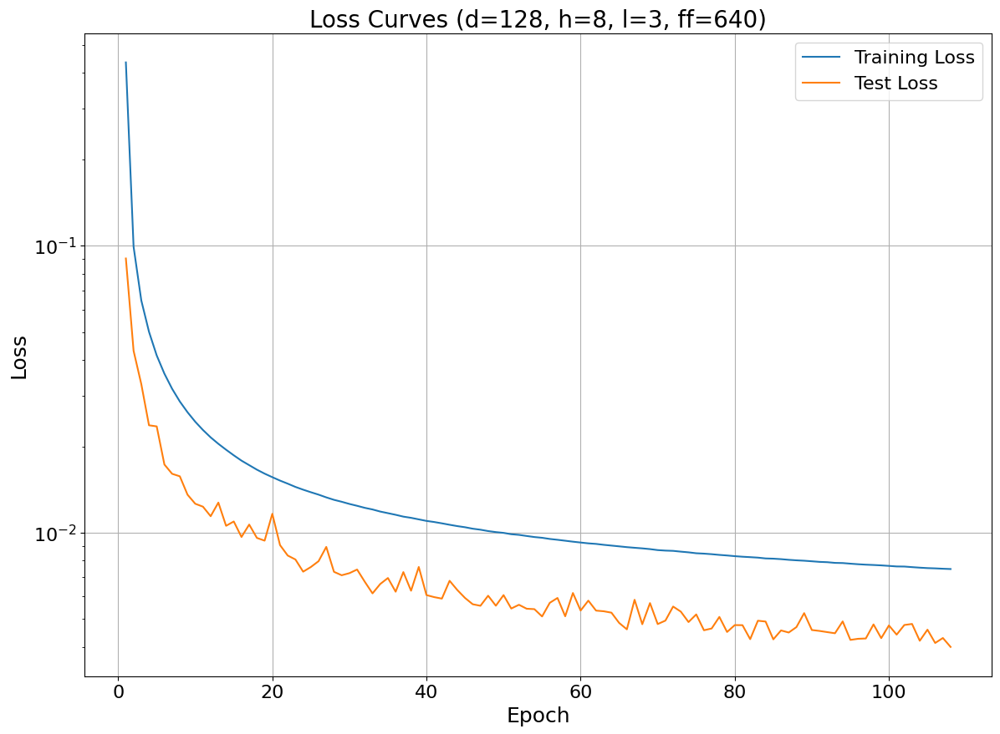

In [20]:
plot_loss_curves(
    train_losses,
    test_losses,
    d_model=config['d_model'],
    n_heads=config['n_heads'],
    n_layers=config['n_layers'],
    d_ff=config['d_ff']
    )

Biomass_Ecoli_core_flux:
------------------------------------------------------------
Biomass_Ecoli_core_flux token index: 12
injected medium slot: False
y_true range: 5.980537389405072e-05 to 2.454660654067993
y_pred range: -0.02786371111869812 to 2.528799295425415


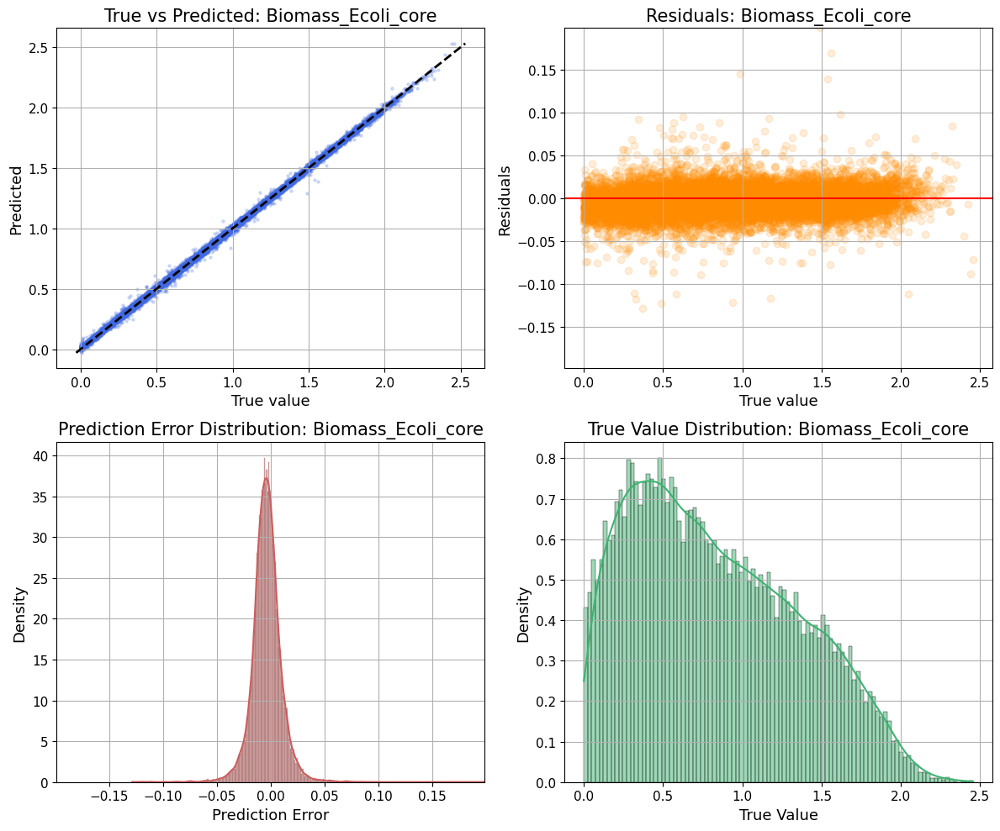

GLUDy_flux:
------------------------------------------------------------
GLUDy_flux token index: 52
injected medium slot: False
y_true range: -10.713763236999512 to 24.10970115661621
y_pred range: -10.779291152954102 to 24.157978057861328


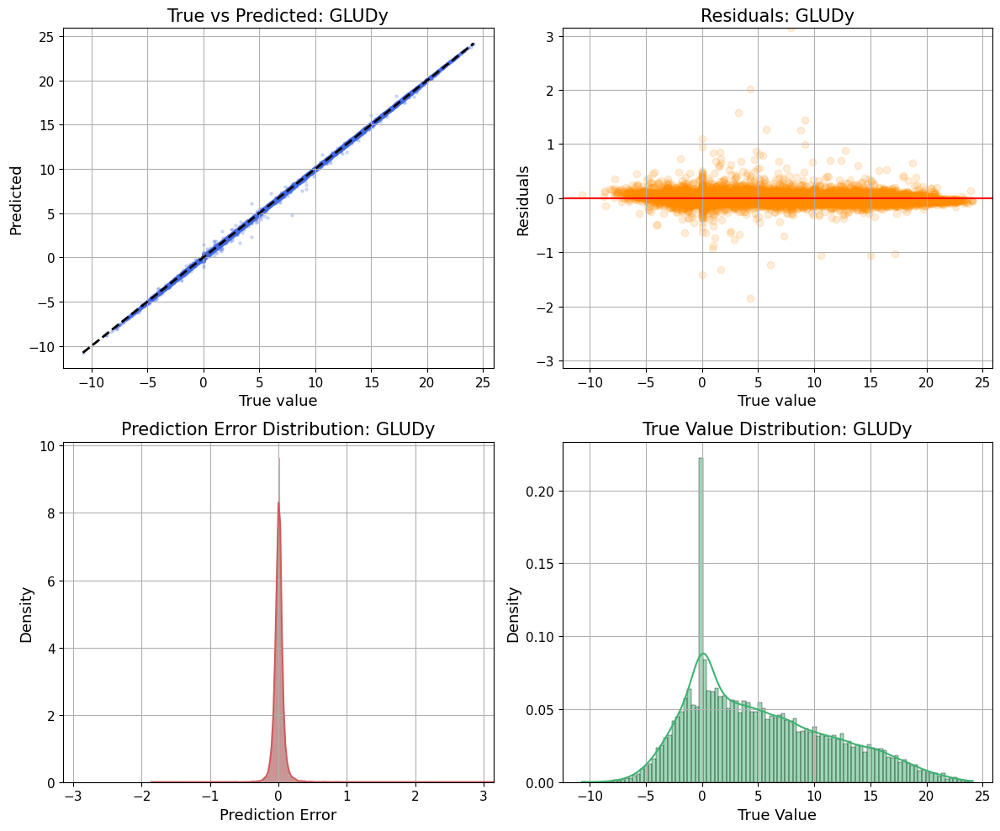

H2Ot_flux:
------------------------------------------------------------
H2Ot_flux token index: 57
injected medium slot: False
y_true range: -58.15304183959961 to 28.555408477783203
y_pred range: -58.751895904541016 to 27.934141159057617


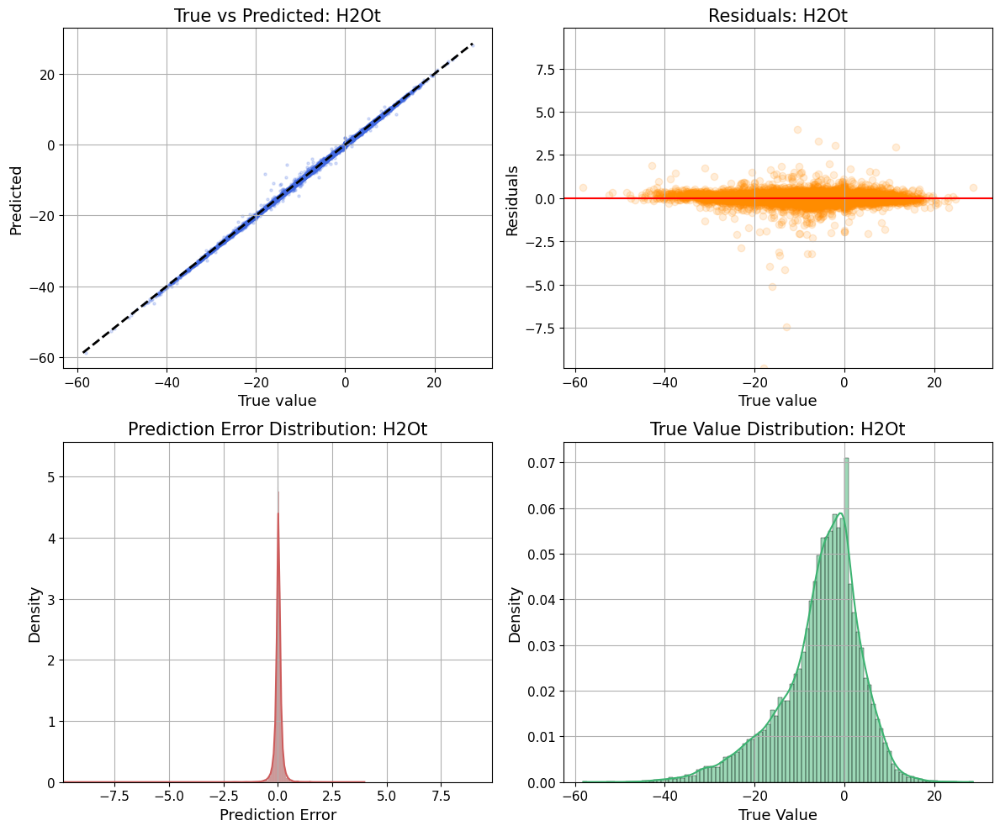

SUCCt3_flux:
------------------------------------------------------------
SUCCt3_flux token index: 87
injected medium slot: False
y_true range: -1.1163749402177698e-14 to 17.278289794921875
y_pred range: -0.18177057802677155 to 17.13930892944336


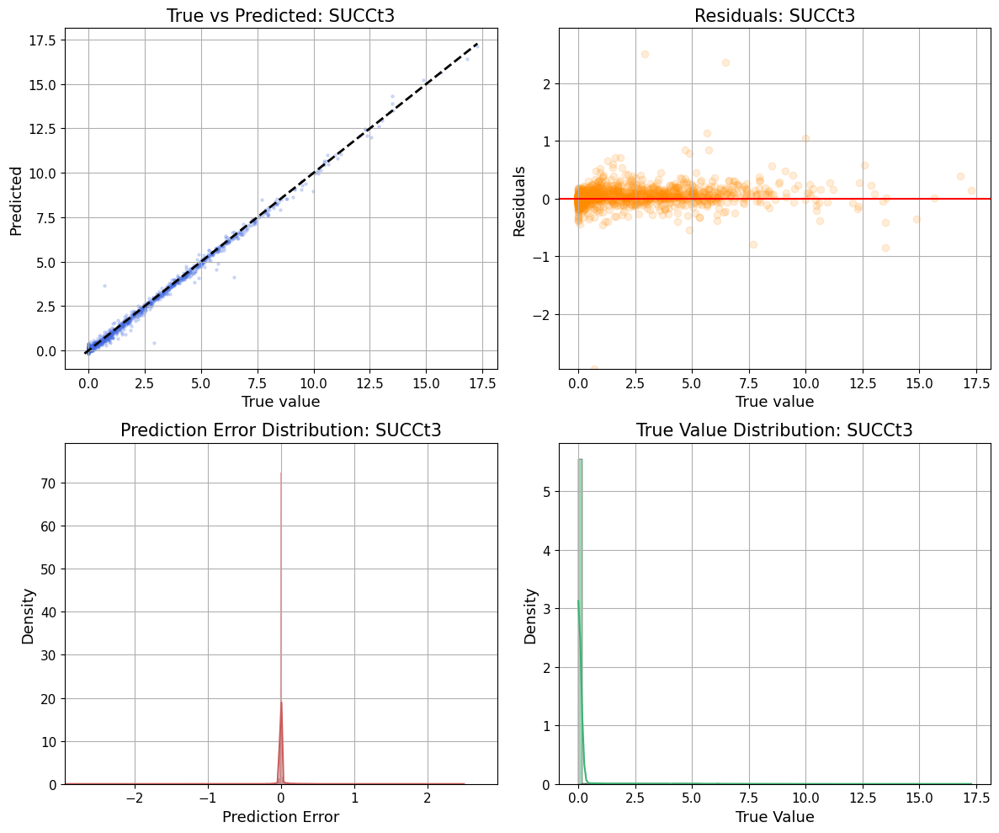

GLUN_flux:
------------------------------------------------------------
GLUN_flux token index: 53
injected medium slot: False
y_true range: -1.4272675626615596e-15 to 28.778430938720703
y_pred range: -0.28734588623046875 to 28.732553482055664


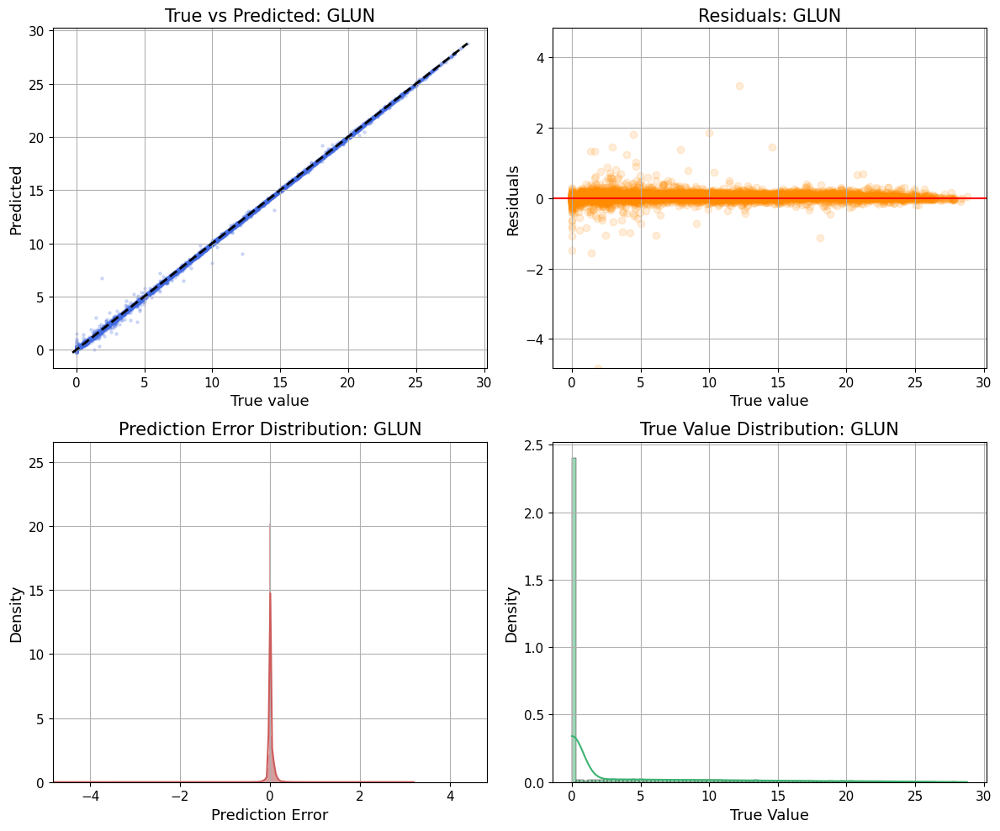

PGM_flux:
------------------------------------------------------------
PGM_flux token index: 76
injected medium slot: False
y_true range: -35.9675178527832 to 8.35302448272705
y_pred range: -36.24812698364258 to 8.404753684997559


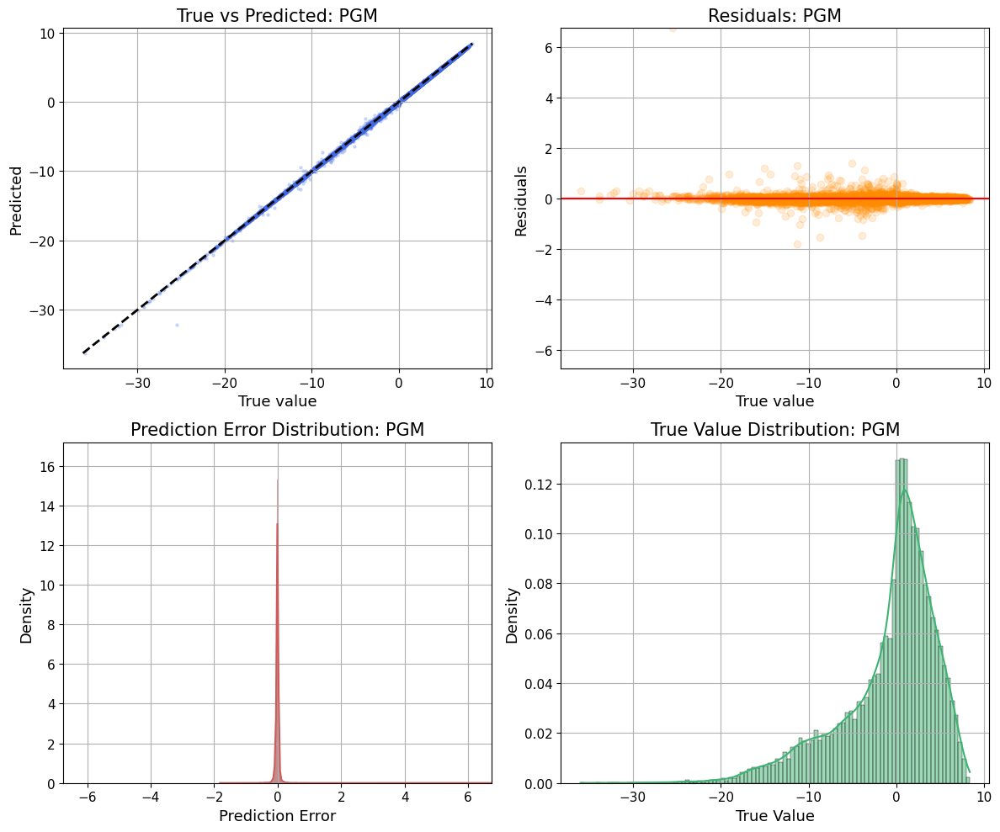

EX_glc__D_e_flux:
------------------------------------------------------------
EX_glc__D_e_flux token index: 27
injected medium slot: True
y_true range: -10.0 to 0.0
y_pred range: -10.096105575561523 to 0.19758033752441406


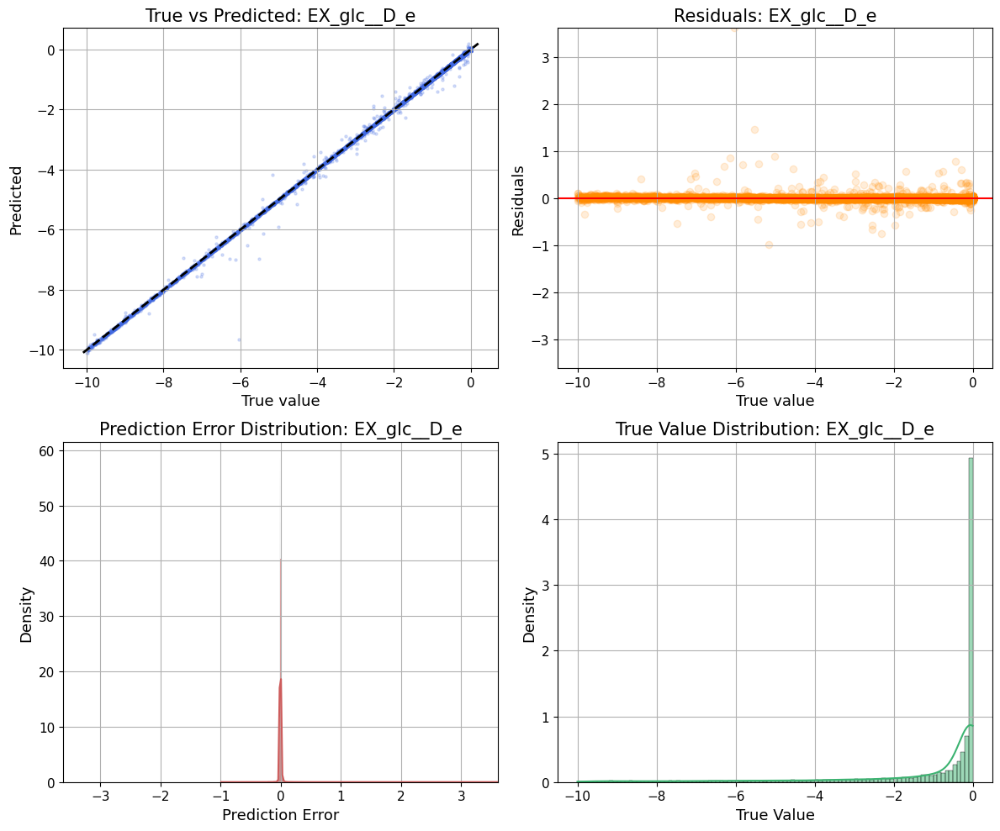

In [21]:
diagnostics_to_plot = ['Biomass_Ecoli_core_flux', 'GLUDy_flux', 'H2Ot_flux', 'SUCCt3_flux', 'GLUN_flux', 'PGM_flux', 'EX_glc__D_e_flux']

for flux_name in diagnostics_to_plot:
    save_path = f"{pic_dir}/{model_name}_{flux_name}"
    print(f'{flux_name}:')
    print(60 * '-')
    plot_flux(model, X_test, y_test, outputs, flux_name, save_path=save_path)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_pca


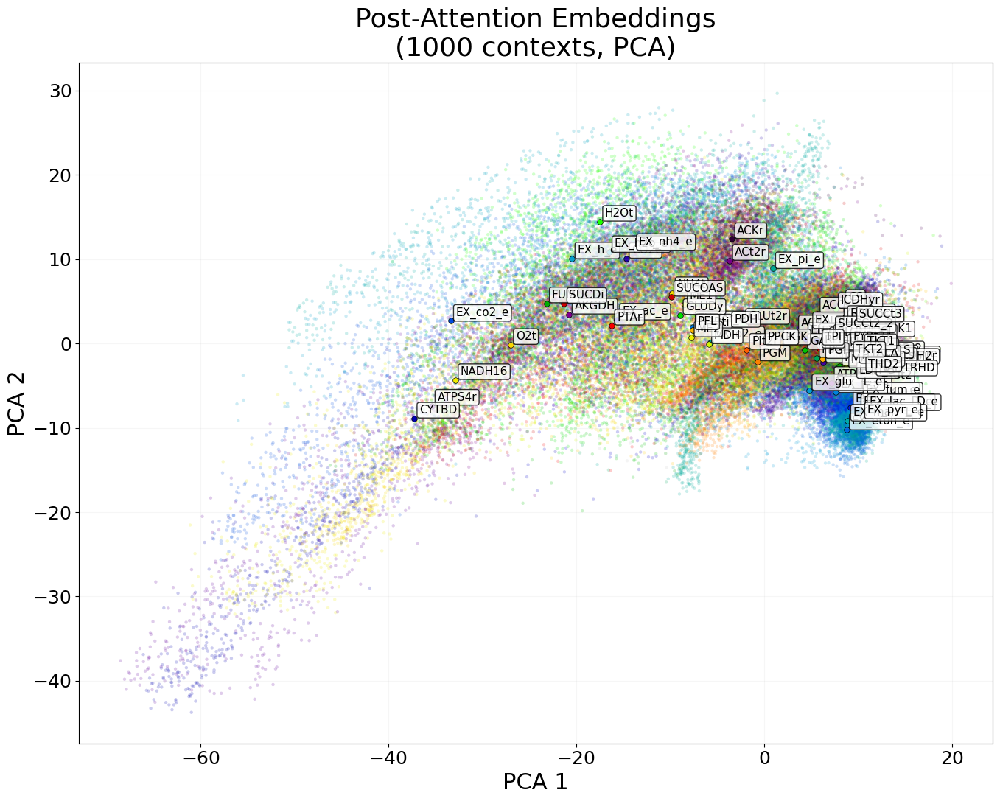

In [22]:
save_path = f"{pic_dir}/{model_name}_pca"

plot_post_attention_real_context(
    model,
    token_names=outputs,
    X_test=X_test,
    method="pca",
    n_components=2,
    n_samples=1000,
    save_path=save_path
)

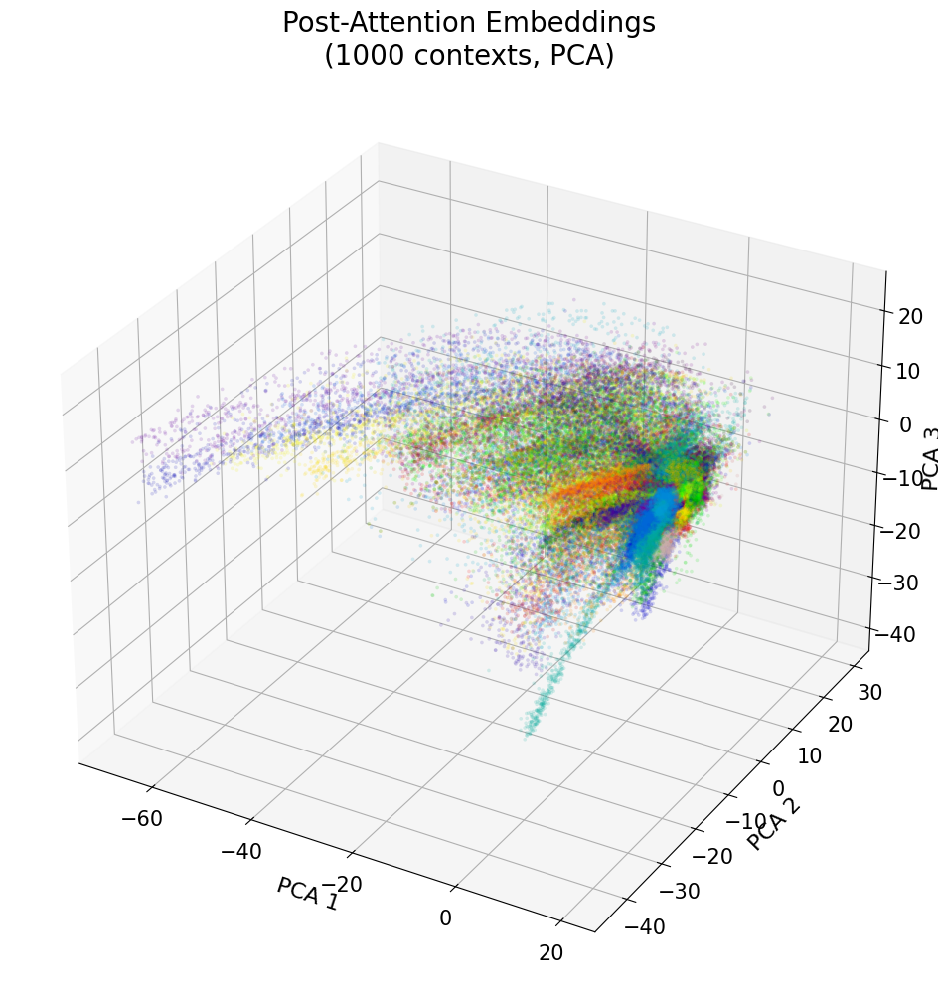

In [23]:
plot_post_attention_real_context(
    model,
    token_names=outputs,
    X_test=X_test,
    method="pca",
    n_components=3,
    n_samples=1000,
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne


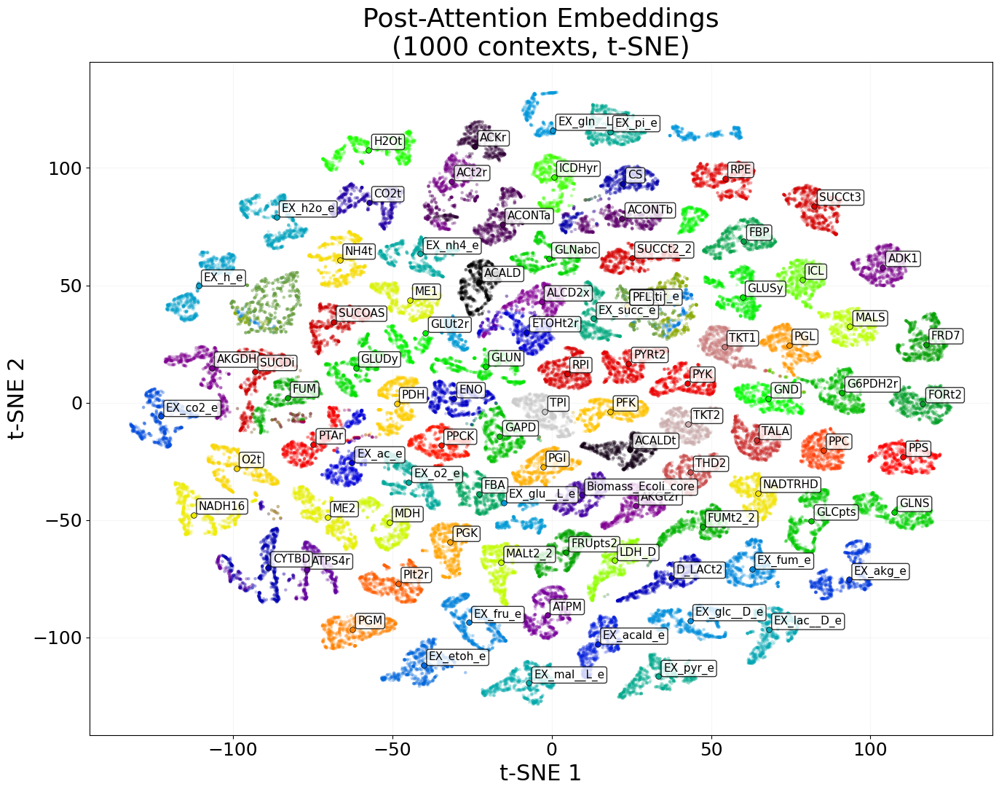

In [24]:
save_path = f"{pic_dir}/{model_name}_tsne"

plot_post_attention_real_context(
    model,
    token_names=outputs,
    X_test=X_test,
    method="tsne",
    n_components=2,
    n_samples=1000,
    perplexity=30.0,
    save_path=save_path
)

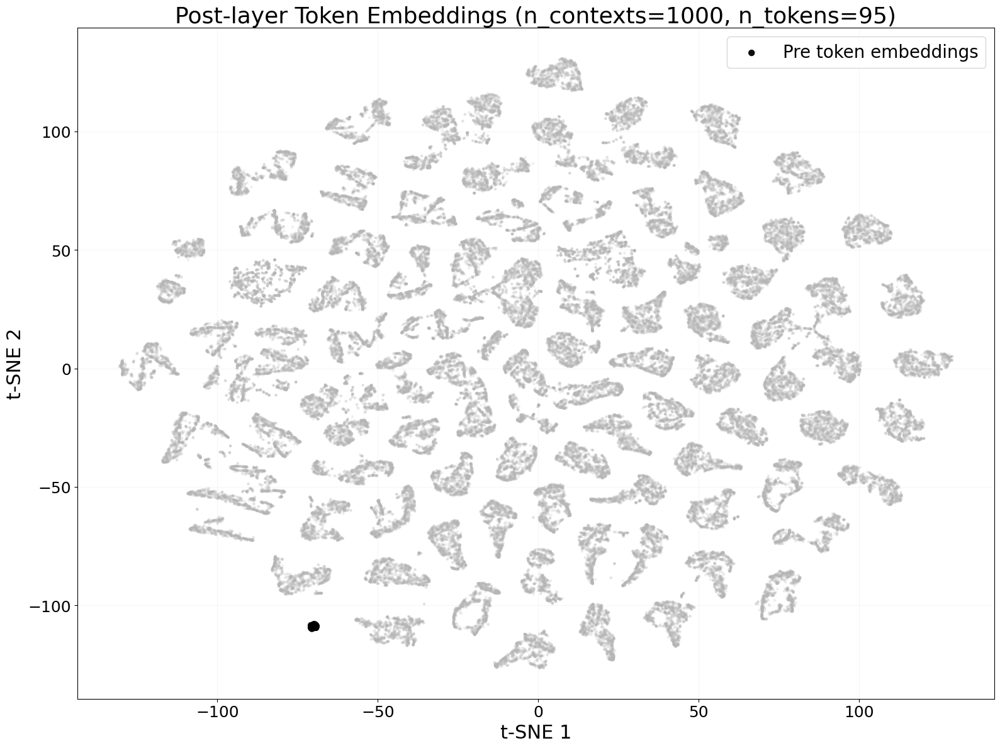

In [25]:
plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    n_samples=1000,
    perplexity=50.0,
    annotate=False,
    sample_color_mode="gray",
    show_pre_embeddings=True,
    highlight_diverse_samples=False,
    n_diverse_samples=0,
)

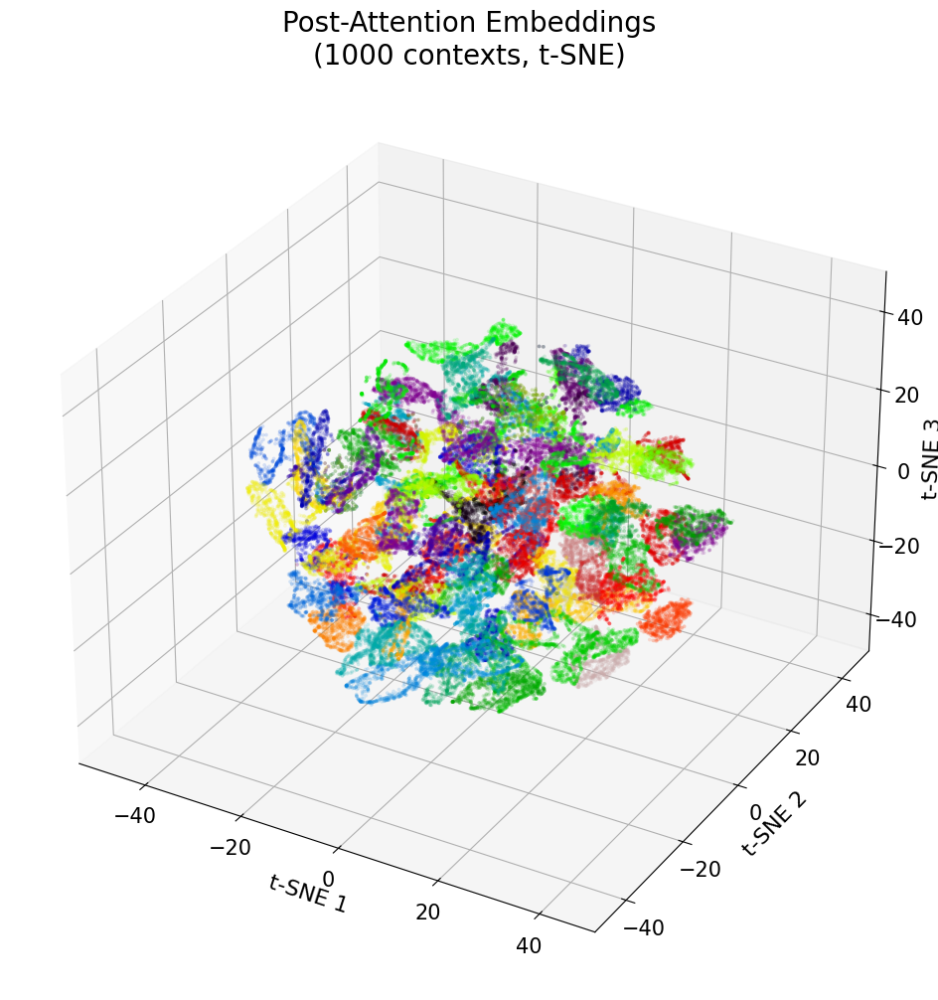

In [26]:
plot_post_attention_real_context(
    model,
    token_names=outputs,
    X_test=X_test,
    method="tsne",
    n_components=3,
    n_samples=1000,
    perplexity=40.0
)

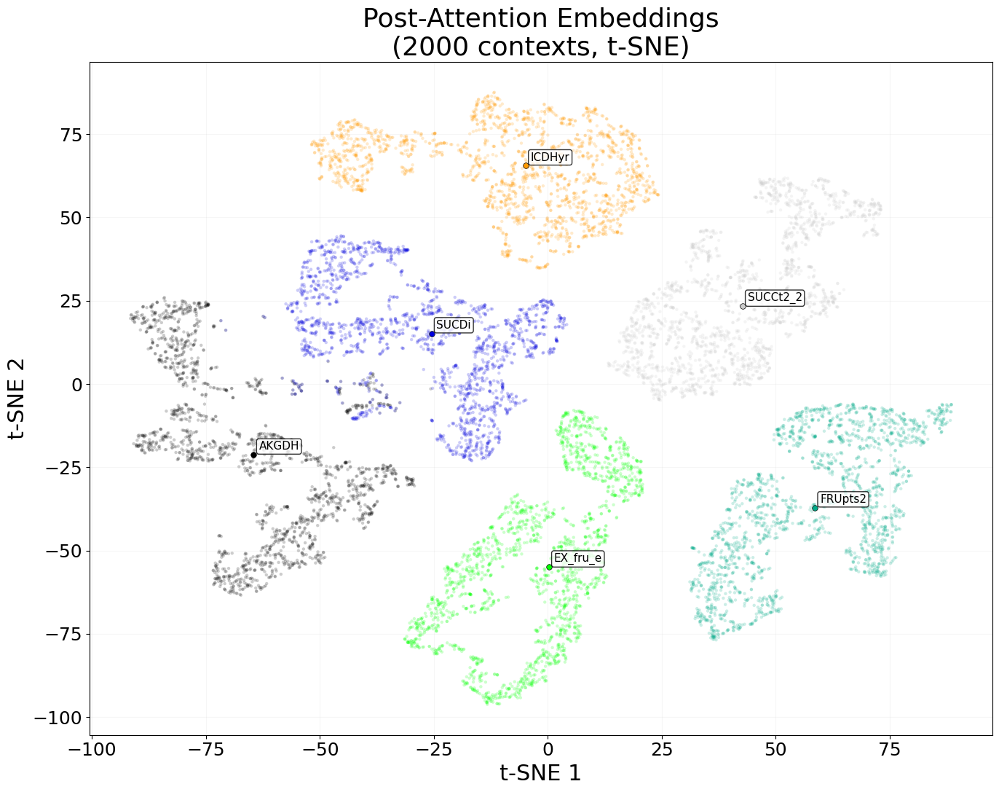

In [27]:
# Use only subset of tokens
'''
glycolysis_tokens = [
    "EX_glc__D_e_flux", "GLCpts_flux",
    "PGI_flux", "PFK_flux", "FBA_flux", "TPI_flux",
    "GAPD_flux", "PGK_flux", "PGM_flux", "ENO_flux", "PYK_flux",
]
idxs = [outputs.index(t) for t in glycolysis_tokens if t in outputs]

tca_tokens = [
    "PDH_flux", "CS_flux", "ACONTa_flux", "ACONTb_flux", "ICDHyr_flux",
    "AKGDH_flux", "SUCOAS_flux", "SUCDi_flux", "FUM_flux", "MDH_flux",
    "SUCCt2_2_flux", "SUCCt3_flux",
]
idxs = [outputs.index(t) for t in tca_tokens if t in outputs]

ppp_tokens = [
    "G6PDH2r_flux", "PGL_flux", "GND_flux", "RPE_flux", "RPI_flux",
    "TKT1_flux", "TKT2_flux", "TALA_flux",
]
idxs = [outputs.index(t) for t in ppp_tokens if t in outputs]

fermentation_tokens = [
    "PFL_flux", "FORt2_flux", "FORti_flux", "EX_for_e_flux",
    "LDH_D_flux", "D_LACt2_flux", "EX_lac__D_e_flux",
    "ACALD_flux", "ACALDt_flux", "ALCD2x_flux", "ETOHt2r_flux", "EX_etoh_e_flux",
    "PTAr_flux", "ACKr_flux", "ACt2r_flux", "EX_ac_e_flux",
]
idxs = [outputs.index(t) for t in fermentation_tokens if t in outputs]

resp_tokens = [
    "NADH16_flux", "NADTRHD_flux", "THD2_flux", "CYTBD_flux",
    "ATPS4r_flux", "ATPM_flux", "O2t_flux",
    "EX_o2_e_flux", "EX_co2_e_flux", "CO2t_flux",
]
idxs = [outputs.index(t) for t in resp_tokens if t in outputs]
'''
test_tokens = [
    "AKGDH_flux", "SUCDi_flux", "FRUpts2_flux", "EX_fru_e_flux", "ICDHyr_flux", "SUCCt2_2_flux",
]
idxs = [outputs.index(t) for t in test_tokens if t in outputs]

plot_post_attention_real_context(
    model, 
    outputs, 
    X_test, 
    token_indices=idxs, 
    method="tsne", 
    n_components=2,
    n_samples=2000,
    perplexity=30.0
)

Grouped t-SNE plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_group_pathway


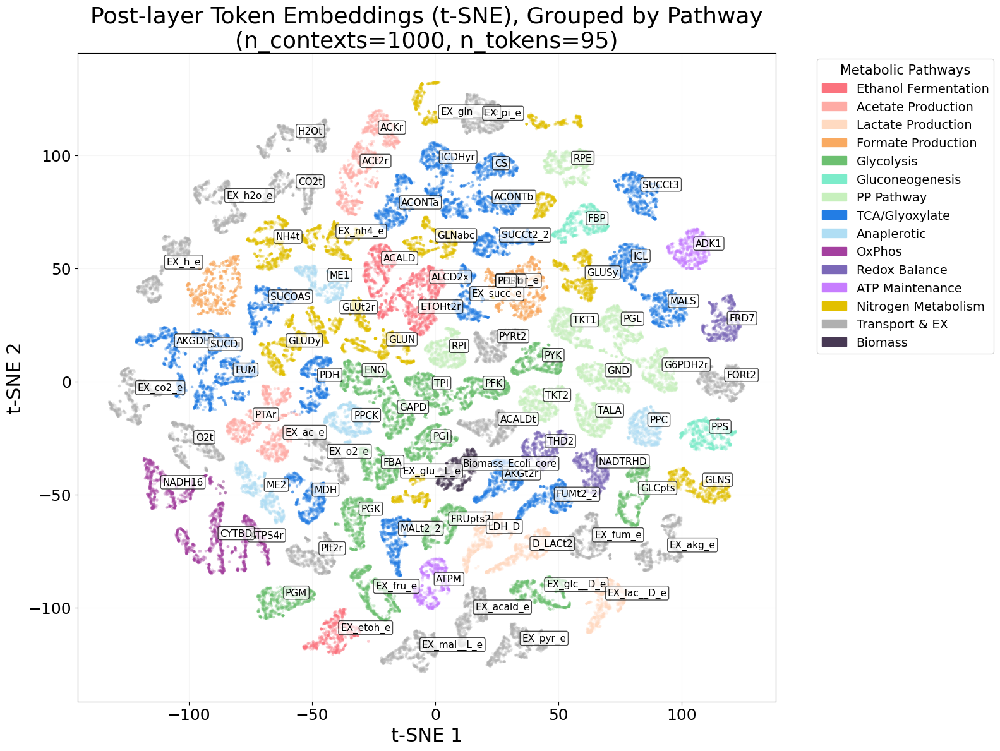

In [28]:
save_path = f"{pic_dir}/{model_name}_tsne_group_pathway"

plot_post_attention_grouped_tsne(
    model,
    outputs,
    X_test,
    n_samples=1000,
    perplexity=30.0,
    token_indices=None,   # all tokens
    annotate=True,
    save_path=save_path
)

Grouped t-SNE plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_group_spearman


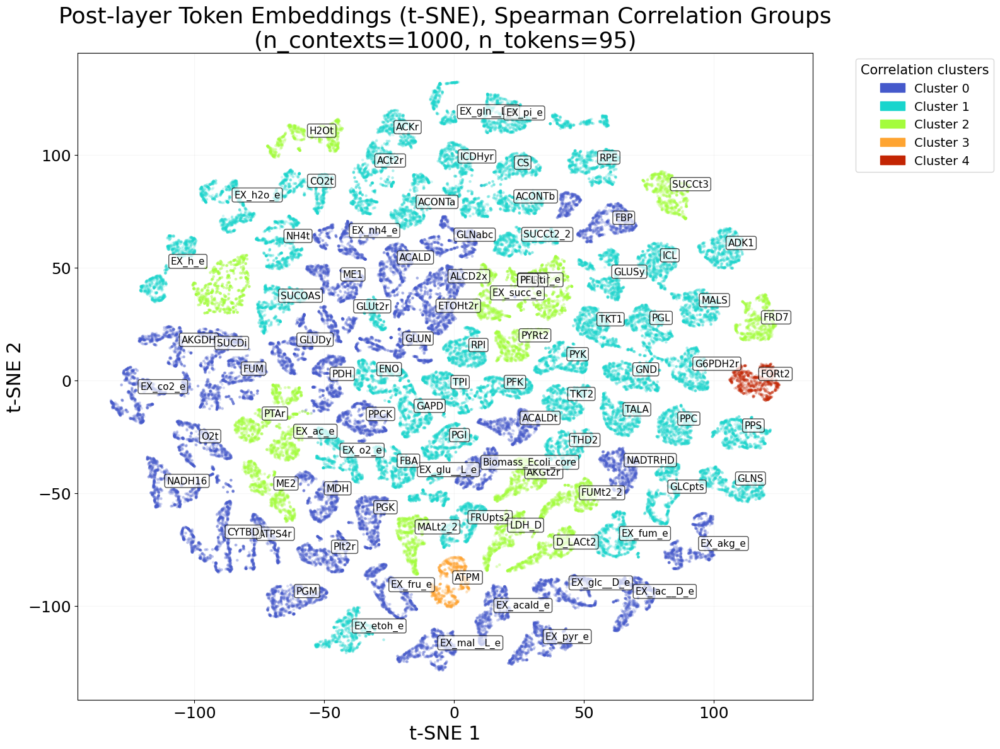

In [29]:
save_path = f"{pic_dir}/{model_name}_tsne_group_spearman"

plot_post_attention_grouped_tsne(
    model,
    outputs,
    X_test,
    n_samples=1000,
    perplexity=30.0,
    token_indices=None,
    annotate=True,
    coloring="corr",
    corr_data_path=DATA_PATH,
    corr_n_clusters=5,
    corr_use_abs=False,
    save_path=save_path
)

Grouped t-SNE plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_group_stoich


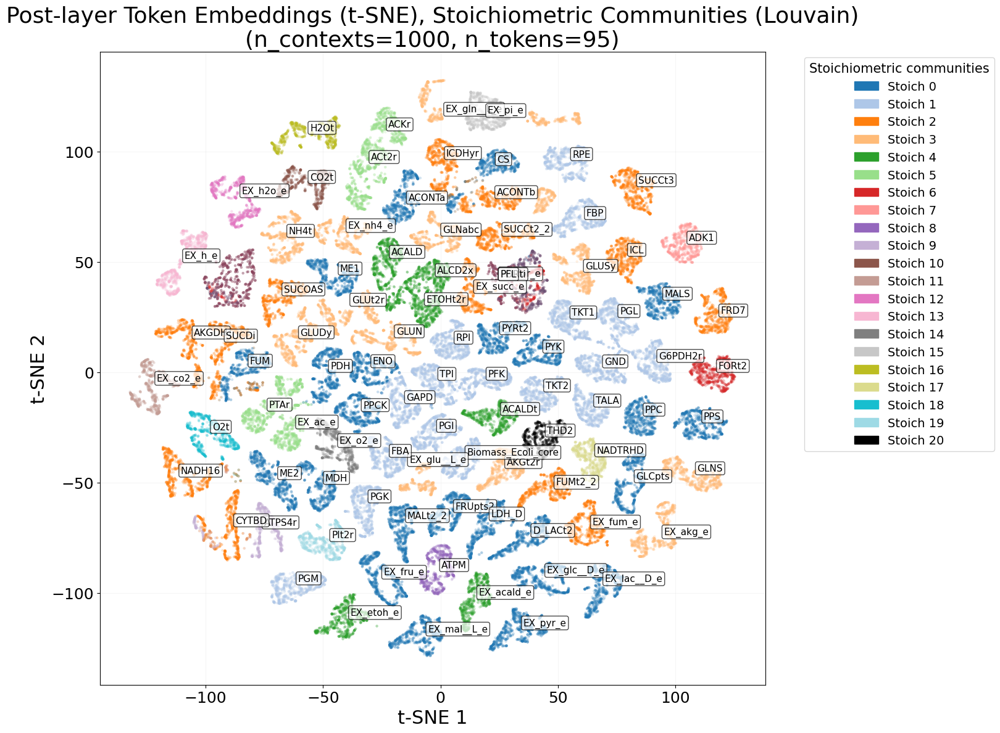

In [30]:
save_path = f"{pic_dir}/{model_name}_tsne_group_stoich"

plot_post_attention_grouped_tsne(
    model,
    outputs,
    X_test,
    coloring="stoich",
    reducer="tsne",
    perplexity=30.0,
    annotate=True,
    save_path=save_path
)

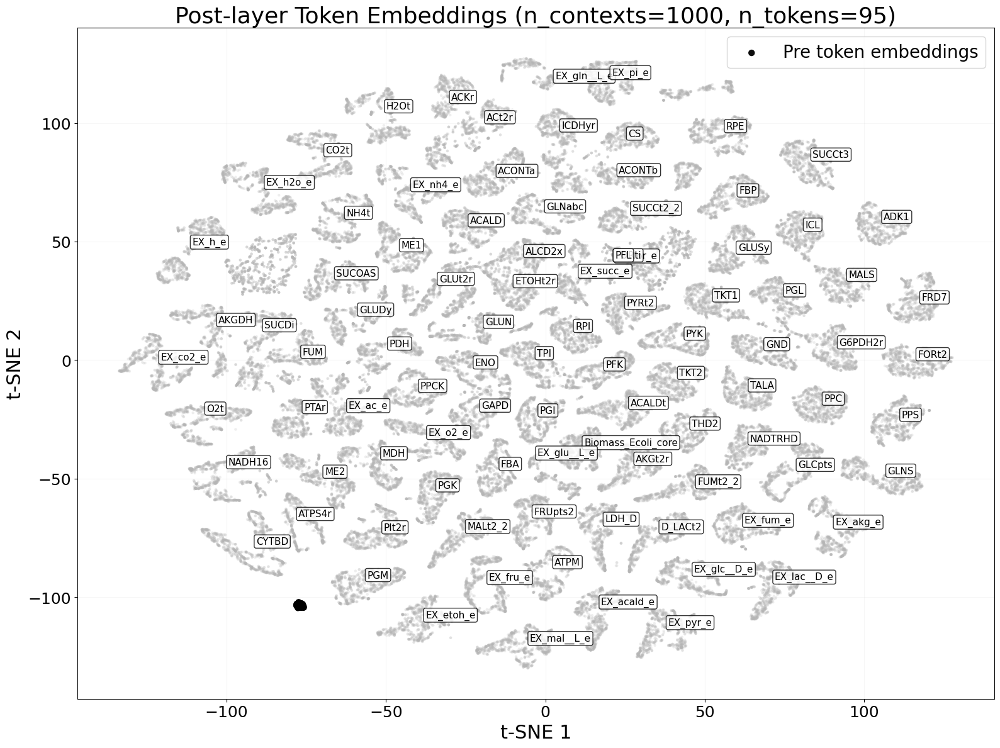

In [31]:
plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    n_samples=1000,
    perplexity=30.0,
    annotate=True,
    sample_color_mode="gray",
    show_pre_embeddings=True,
    highlight_diverse_samples=False,
    n_diverse_samples=0,
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_similarity


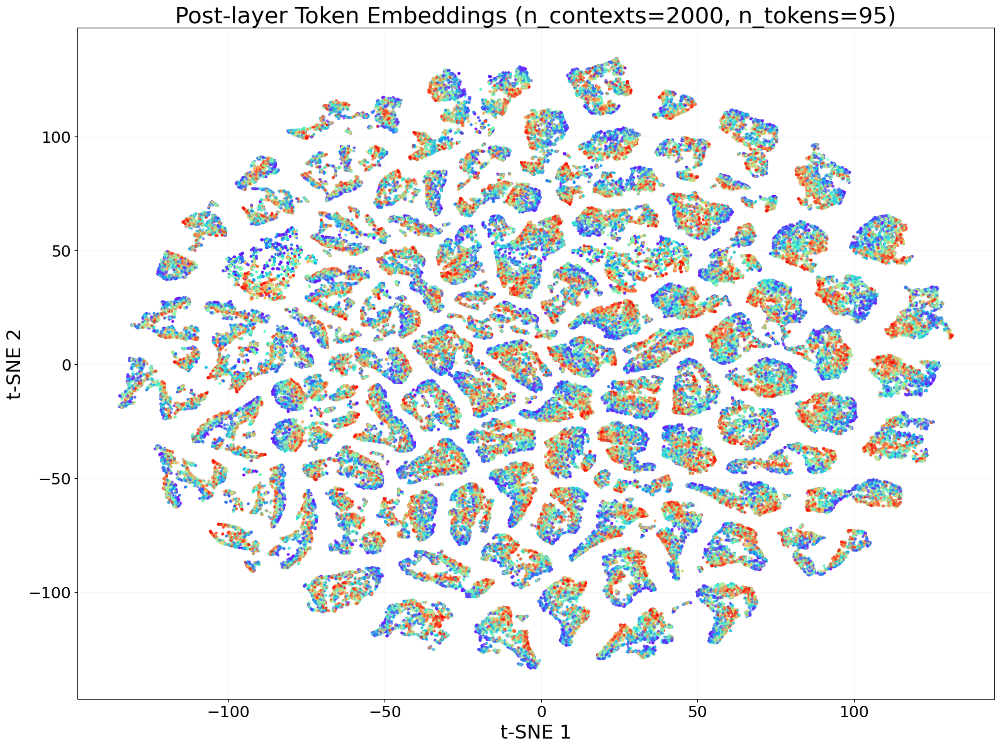

In [32]:
save_path = f"{pic_dir}/{model_name}_tsne_similarity"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    n_samples=2000,
    perplexity=30.0,
    sample_color_mode="rainbow",
    annotate=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_glycolysis_gray_pre


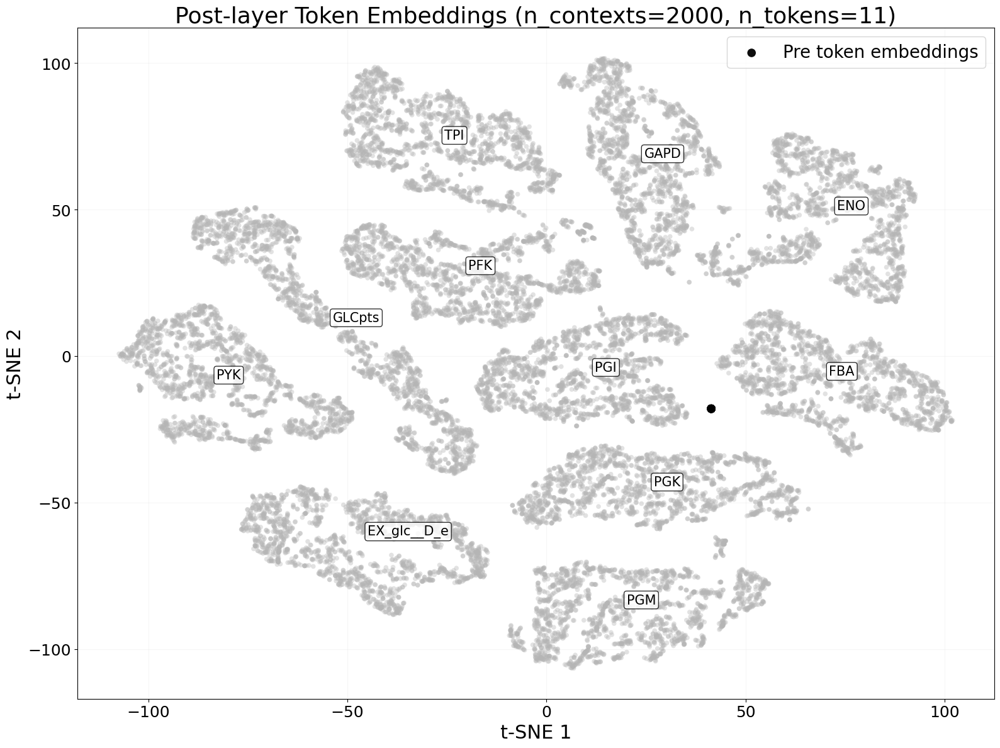

In [33]:
glycolysis_tokens = [
    "EX_glc__D_e_flux", "GLCpts_flux",
    "PGI_flux", "PFK_flux", "FBA_flux", "TPI_flux",
    "GAPD_flux", "PGK_flux", "PGM_flux", "ENO_flux", "PYK_flux",
]
idxs = [outputs.index(f) for f in glycolysis_tokens if f in outputs]
save_path = f"{pic_dir}/{model_name}_tsne_glycolysis_gray_pre"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,   # subset of flux token indices
    n_samples=2000,
    perplexity=30.0,
    annotate=True,
    annotate_fontsize=15,
    sample_color_mode="gray",
    show_pre_embeddings=True,
    highlight_diverse_samples=False,
    n_diverse_samples=0,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_glycolysis


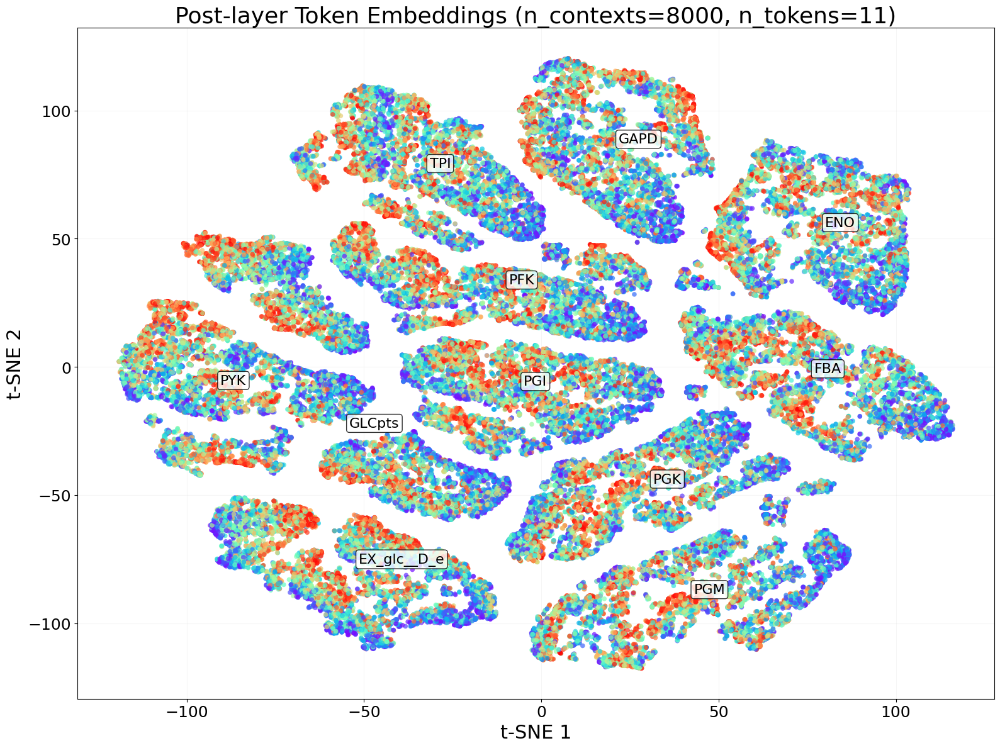

In [34]:
save_path = f"{pic_dir}/{model_name}_tsne_glycolysis"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=8000,
    perplexity=40.0,
    sample_color_mode="rainbow",
    annotate=True,
    annotate_fontsize=16,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_ppp


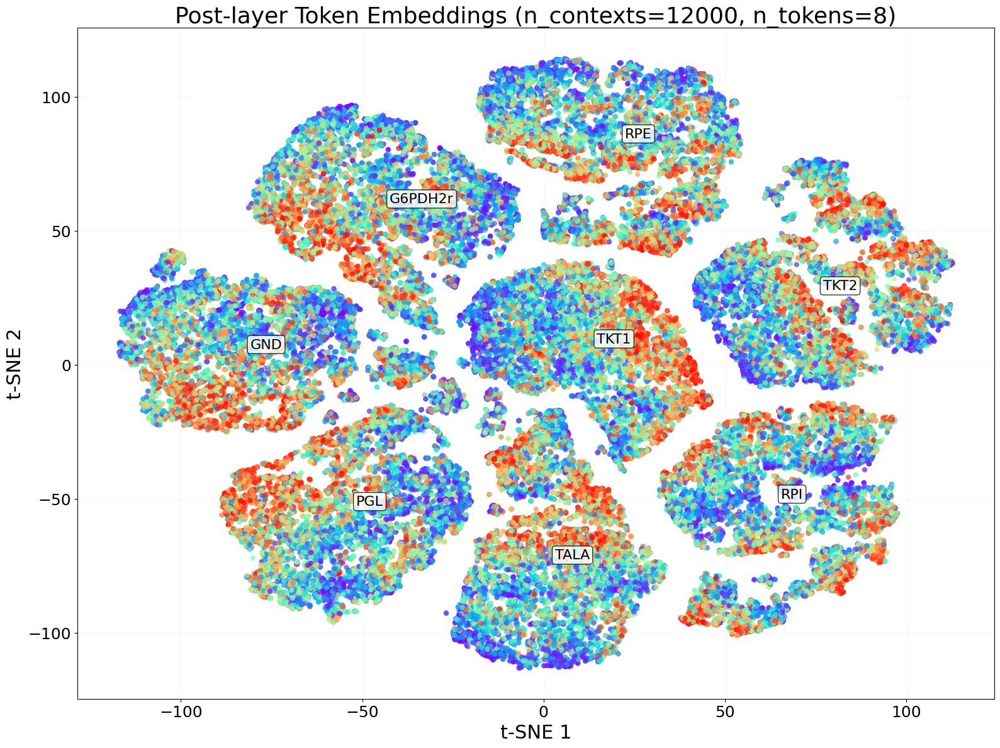

In [35]:
ppp_tokens = [
    "G6PDH2r_flux", "PGL_flux", "GND_flux", "RPE_flux", "RPI_flux",
    "TKT1_flux", "TKT2_flux", "TALA_flux",
]
idxs = [outputs.index(t) for t in ppp_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_ppp"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=12000,
    perplexity=40.0,
    sample_color_mode="rainbow",
    annotate=True,
    annotate_fontsize=16,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_tca


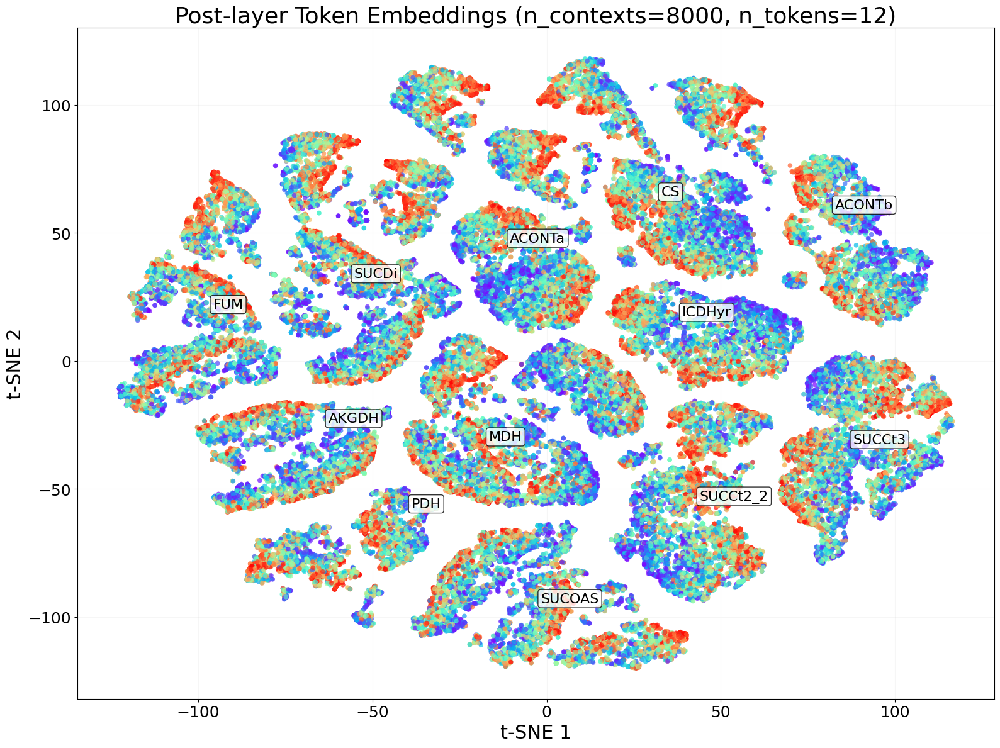

In [36]:
tca_tokens = [
    "PDH_flux", "CS_flux", "ACONTa_flux", "ACONTb_flux", "ICDHyr_flux",
    "AKGDH_flux", "SUCOAS_flux", "SUCDi_flux", "FUM_flux", "MDH_flux",
    "SUCCt2_2_flux", "SUCCt3_flux",
]
idxs = [outputs.index(t) for t in tca_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_tca"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=8000,
    perplexity=40.0,
    sample_color_mode="rainbow", # "coolwarm",
    annotate=True,
    annotate_fontsize=16,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_ferm


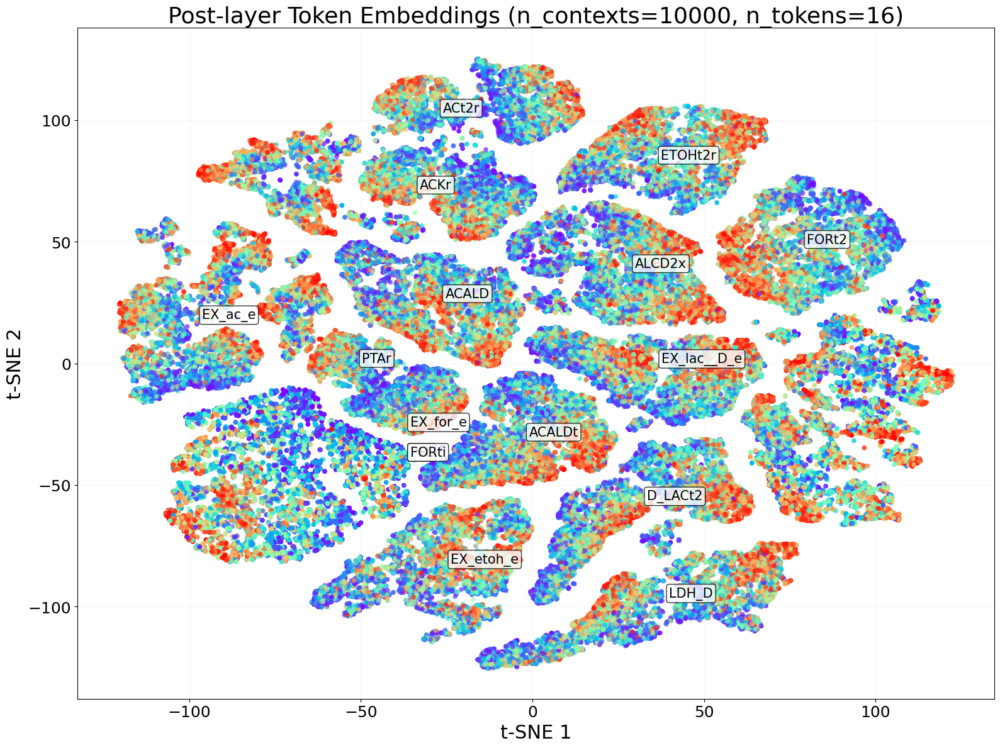

In [37]:
fermentation_tokens = [
    "PFL_flux", "FORt2_flux", "FORti_flux", "EX_for_e_flux",
    "LDH_D_flux", "D_LACt2_flux", "EX_lac__D_e_flux",
    "ACALD_flux", "ACALDt_flux", "ALCD2x_flux", "ETOHt2r_flux", "EX_etoh_e_flux",
    "PTAr_flux", "ACKr_flux", "ACt2r_flux", "EX_ac_e_flux",
]
idxs = [outputs.index(t) for t in fermentation_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_ferm"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=10000,
    perplexity=40.0,
    sample_color_mode="rainbow", # "viridis",
    annotate=True,
    annotate_fontsize=15,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_resp


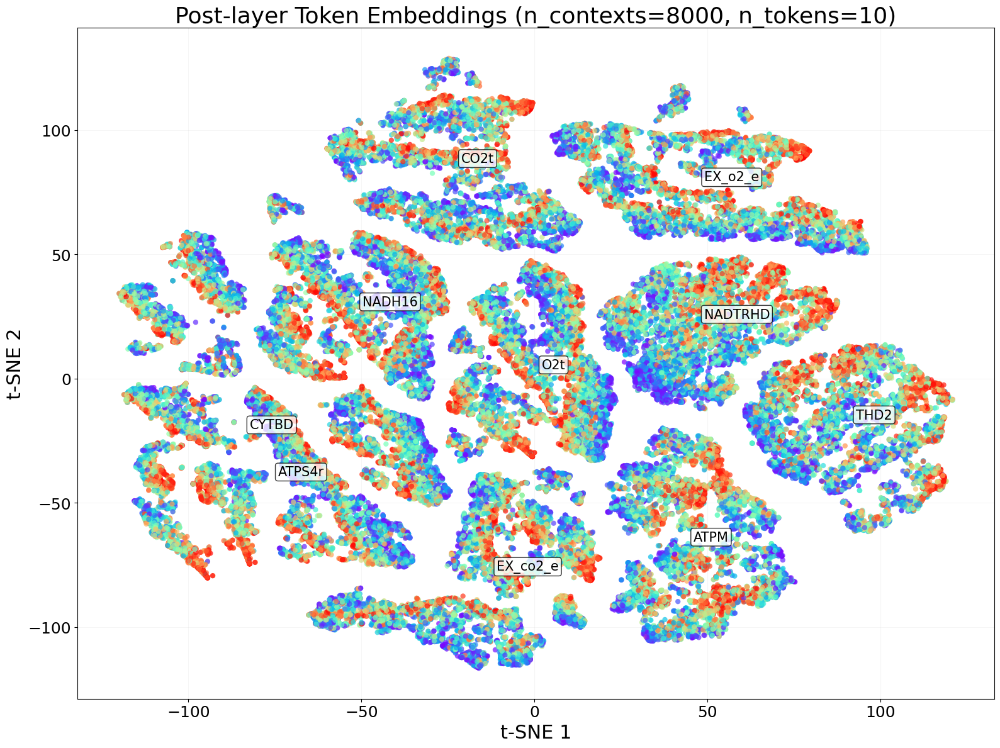

In [38]:
resp_tokens = [
    "NADH16_flux", "NADTRHD_flux", "THD2_flux", "CYTBD_flux",
    "ATPS4r_flux", "ATPM_flux", "O2t_flux",
    "EX_o2_e_flux", "EX_co2_e_flux", "CO2t_flux",
]
idxs = [outputs.index(t) for t in resp_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_resp"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=8000,
    perplexity=40.0,
    sample_color_mode="rainbow", # "plasma",
    annotate=True,
    annotate_fontsize=15,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_simtokens


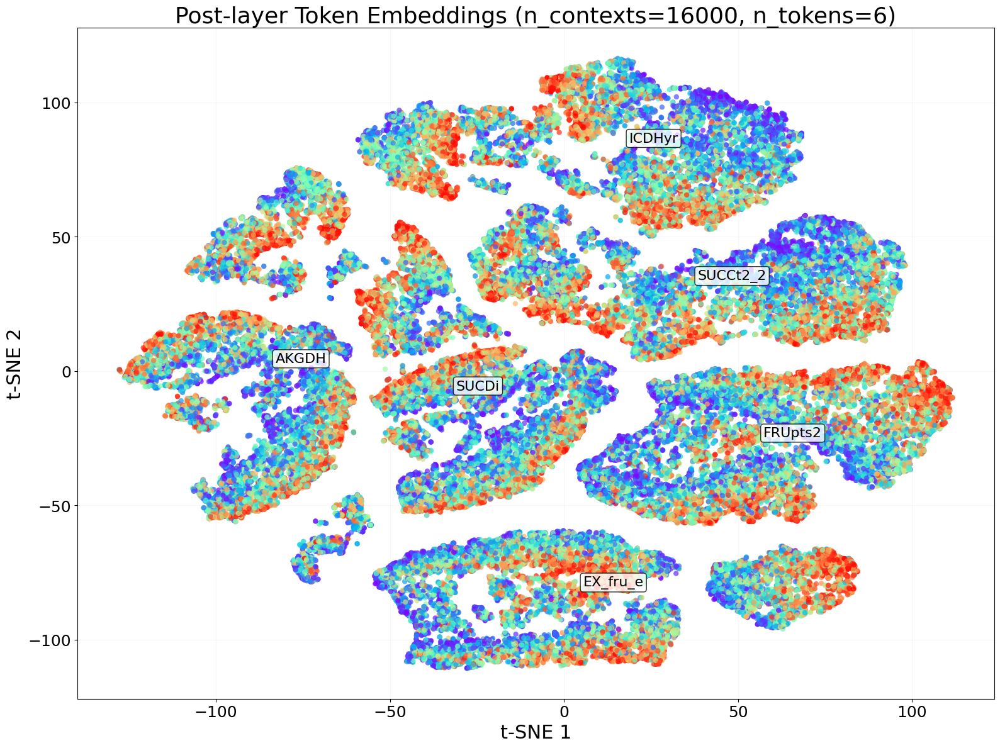

In [39]:
similar_tokens = [
    "AKGDH_flux", "SUCDi_flux", "FRUpts2_flux", "EX_fru_e_flux", "ICDHyr_flux", "SUCCt2_2_flux",
]
idxs = [outputs.index(t) for t in similar_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_simtokens"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=16000,
    perplexity=50.0,
    sample_color_mode="rainbow", # "viridis",
    annotate=True,
    annotate_fontsize=16,
    highlight_diverse_samples=False,
    save_path=save_path
)

Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_tsne_simtokens2


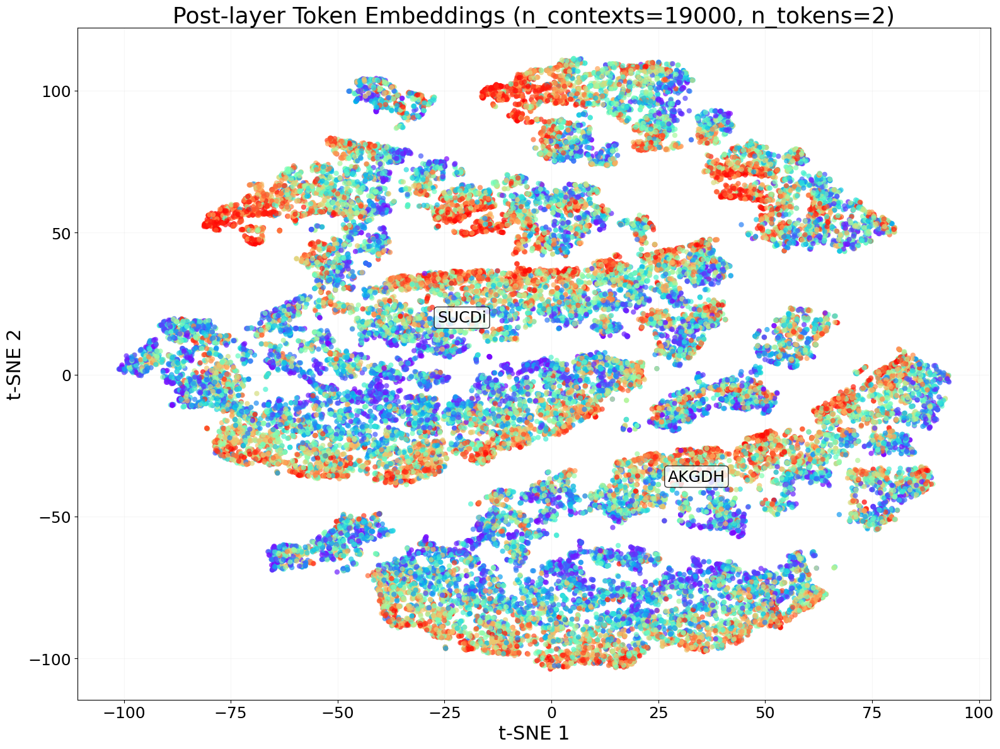

In [40]:
similar_tokens = [
    "AKGDH_flux", "SUCDi_flux", 
]
idxs = [outputs.index(t) for t in similar_tokens if t in outputs]

save_path = f"{pic_dir}/{model_name}_tsne_simtokens2"

plot_post_attn_tsne_gray(
    model,
    token_names=outputs,
    X_test=X_test,
    token_indices=idxs,
    n_samples=19000,
    perplexity=50.0,
    sample_color_mode="rainbow",
    annotate=True,
    annotate_fontsize=18,
    highlight_diverse_samples=False,
    save_path=save_path
)

c:\Users\truok\projects\metabolic-NN\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\truok\projects\metabolic-NN\venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


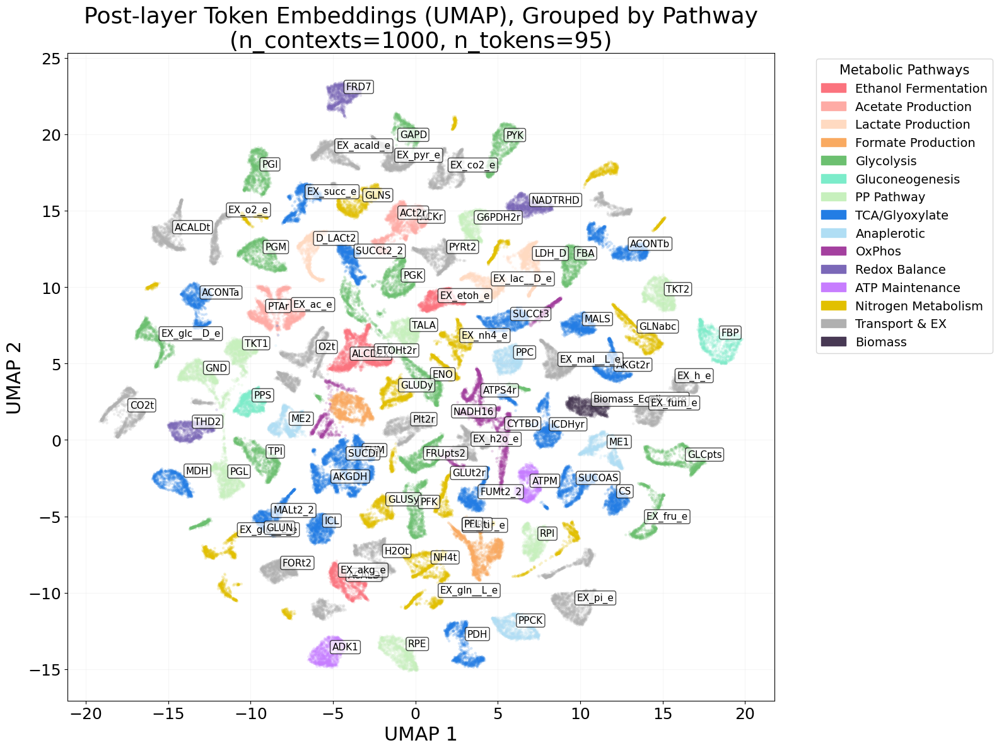

In [41]:
plot_post_attention_grouped_tsne(
    model,
    outputs,
    X_test,
    n_samples=1000,
    perplexity=30.0,
    token_indices=None,
    annotate=True,
    reducer='umap',
    n_neighbors=50,          # UMAP only
    min_dist=0.5,            # UMAP only
)

In [42]:
# Pathway subset example
'''
idxs = [outputs.index("Biomass_Ecoli_core_flux"), outputs.index("GLUDy_flux")]
plot_post_attention_grouped_tsne(
    model,
    outputs,
    X_test,
    token_indices=idxs,
    n_samples=1000,
    perplexity=30.0,
    annotate=True
)
'''

'\nidxs = [outputs.index("Biomass_Ecoli_core_flux"), outputs.index("GLUDy_flux")]\nplot_post_attention_grouped_tsne(\n    model,\n    outputs,\n    X_test,\n    token_indices=idxs,\n    n_samples=1000,\n    perplexity=30.0,\n    annotate=True\n)\n'

c:\Users\truok\projects\metabolic-NN\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\truok\projects\metabolic-NN\venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Plot saved to ./pics/2026-10-19/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640/ecoli_core_10M_signed_pfba_d128_h8_l3_ff640_umap


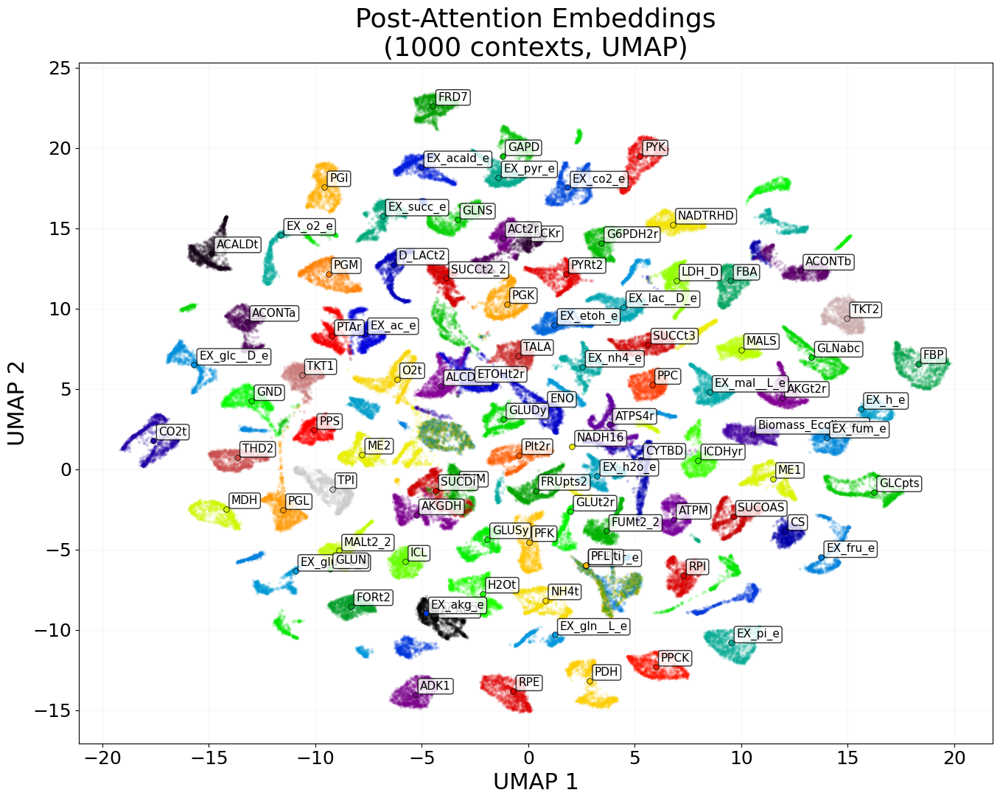

In [43]:
save_path = f"{pic_dir}/{model_name}_umap"

plot_post_attention_real_context(
    model,
    token_names=outputs,
    X_test=X_test,
    method="umap",
    n_components=2,
    n_neighbors=50, 
    min_dist=0.5,
    save_path=save_path
)

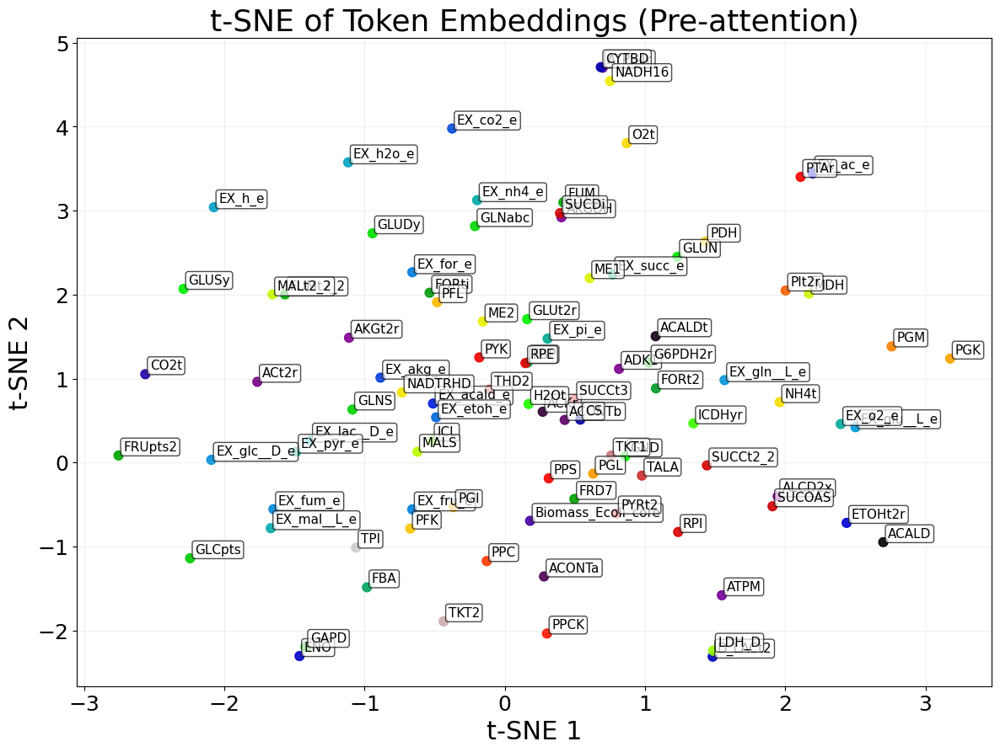

In [44]:
# pre-attention embeddings

plot_pre_attention_embeddings_tsne(
    model,
    outputs,
    perplexity=30.0,
    save_path=None,
    annotate=True
)

In [45]:
# add rmse for individual fluxes
# add average metrics for the model: r2, mae, rmse

metrics = []

model_cpu = model.to("cpu").eval()

with torch.no_grad():
    preds_all_layers, _ = model_cpu(X_test.unsqueeze(-1).to("cpu"), output_subset=None)
    # preds_all_layers: (N, V, n_layers)
    y_pred_full = preds_all_layers[:, :, -1].cpu().numpy()  # (N, V)

y_true_full = y_test.cpu().numpy()  # (N, V)

# Sanity check: token names align with tensor width
V = y_true_full.shape[1]
if len(outputs) != V:
    raise ValueError(f"len(outputs)={len(outputs)} must match V={V}.")

for i, label in enumerate(outputs):
    yt = y_true_full[:, i]
    yp = y_pred_full[:, i]

    # r2 is undefined if yt is constant
    try:
        r2 = r2_score(yt, yp)
    except Exception:
        r2 = float("nan")

    mae = mean_absolute_error(yt, yp)
    rmse = float(np.sqrt(np.mean((yt - yp) ** 2)))
    metrics.append({"flux": label.replace("_flux", ""), "r2": r2, "mae": mae, "rmse": rmse})

df_metrics = pd.DataFrame(metrics)[["flux", "r2", "mae", "rmse"]]

df_metrics["r2"] = df_metrics["r2"].map(lambda x: "nan" if pd.isna(x) else f"{x:.3f}")
df_metrics["mae"] = df_metrics["mae"].map(lambda x: f"{x:.4f}")
df_metrics["rmse"] = df_metrics["rmse"].map(lambda x: f"{x:.4f}")

# Overall model metrics across all samples and all flux outputs
yt_all = y_true_full.ravel()
yp_all = y_pred_full.ravel()
try:
    overall_r2 = r2_score(yt_all, yp_all)
except Exception:
    overall_r2 = float("nan")
overall_mae = mean_absolute_error(yt_all, yp_all)
overall_rmse = float(np.sqrt(np.mean((yt_all - yp_all) ** 2)))

print("\nModel Evaluation Metrics Per Flux:\n")
display(df_metrics)

print("\nOverall Model Metrics (all fluxes pooled):")
print("R2  :", "nan" if pd.isna(overall_r2) else f"{overall_r2:.3f}")
print("MAE :", f"{overall_mae:.4f}")
print("RMSE:", f"{overall_rmse:.4f}")


Model Evaluation Metrics Per Flux:



,flux,r2,mae,rmse
0,ACALD,0.999,0.0393,0.1000
1,ACALDt,1.000,0.0103,0.0440
2,ACKr,0.999,0.0719,0.1505
3,ACONTa,0.999,0.0273,0.0635
4,ACONTb,0.999,0.0281,0.0640
5,ACt2r,0.999,0.0704,0.1495
6,ADK1,0.972,0.0091,0.0241
7,AKGDH,1.000,0.0643,0.1143
8,AKGt2r,1.000,0.0184,0.0427
9,ALCD2x,0.999,0.0337,0.0875



Overall Model Metrics (all fluxes pooled):
R2  : 1.000
MAE : 0.0364
RMSE: 0.0970


In [46]:
# Hard-flux audit: identify difficult fluxes and failure modes
# This cell uses the same y_true_full / y_pred_full arrays as the metric cell above.
# If they do not exist yet, it recomputes predictions from the current model and X_test/y_test.

activity_threshold = 1e-4
tail_quantile = 0.90

if "y_true_full" not in globals() or "y_pred_full" not in globals():
    model_cpu = model.to("cpu").eval()
    with torch.no_grad():
        preds_all_layers, _ = model_cpu(X_test.unsqueeze(-1).to("cpu"), output_subset=None)
        y_pred_full = preds_all_layers[:, :, -1].cpu().numpy()
    y_true_full = y_test.cpu().numpy()


def _safe_r2(yt, yp):
    try:
        return float(r2_score(yt, yp))
    except Exception:
        return float("nan")


def _flux_audit_table(y_true_full, y_pred_full, outputs, activity_threshold=1e-4, tail_quantile=0.90):
    rows = []
    for i, label in enumerate(outputs):
        yt = np.asarray(y_true_full[:, i], dtype=np.float64)
        yp = np.asarray(y_pred_full[:, i], dtype=np.float64)
        err = yt - yp
        abs_true = np.abs(yt)
        abs_pred = np.abs(yp)
        active_true = abs_true > activity_threshold
        active_pred = abs_pred > activity_threshold
        inactive_true = ~active_true

        active_abs = abs_true[active_true]
        if active_abs.size > 0:
            tail_threshold = float(np.quantile(active_abs, tail_quantile))
            tail_mask = abs_true >= tail_threshold
        else:
            tail_threshold = float("nan")
            tail_mask = np.zeros_like(active_true, dtype=bool)

        if tail_mask.any():
            tail_err = err[tail_mask]
            tail_rmse = float(np.sqrt(np.mean(tail_err ** 2)))
            tail_mae = float(np.mean(np.abs(tail_err)))
            tail_bias = float(np.mean(tail_err))
            tail_under_mask = tail_mask & (((yt >= 0) & (yp < yt)) | ((yt < 0) & (yp > yt)))
            tail_under_frac = float(tail_under_mask.sum() / tail_mask.sum())
        else:
            tail_rmse = float("nan")
            tail_mae = float("nan")
            tail_bias = float("nan")
            tail_under_frac = float("nan")

        false_positive = inactive_true & active_pred
        false_negative = active_true & (~active_pred)
        true_range = float(np.max(yt) - np.min(yt))
        rmse = float(np.sqrt(np.mean(err ** 2)))

        rows.append({
            "flux": label.replace("_flux", ""),
            "r2": _safe_r2(yt, yp),
            "mae": float(mean_absolute_error(yt, yp)),
            "rmse": rmse,
            "bias_true_minus_pred": float(np.mean(err)),
            "true_min": float(np.min(yt)),
            "true_max": float(np.max(yt)),
            "pred_min": float(np.min(yp)),
            "pred_max": float(np.max(yp)),
            "true_range": true_range,
            "rmse_over_range": rmse / true_range if true_range > 0 else float("nan"),
            "active_frac_true": float(active_true.mean()),
            "active_frac_pred": float(active_pred.mean()),
            "false_positive_frac_all": float(false_positive.mean()),
            "false_positive_rate_given_inactive": float(false_positive.sum() / max(1, inactive_true.sum())),
            "active_false_negative_rate": float(false_negative.sum() / max(1, active_true.sum())),
            "tail90_threshold": tail_threshold,
            "tail90_rmse": tail_rmse,
            "tail90_mae": tail_mae,
            "tail90_bias_true_minus_pred": tail_bias,
            "tail90_underprediction_frac": tail_under_frac,
        })
    return pd.DataFrame(rows)


flux_audit = _flux_audit_table(
    y_true_full,
    y_pred_full,
    outputs,
    activity_threshold=activity_threshold,
    tail_quantile=tail_quantile,
)

# Data-driven candidate list: high absolute error, weak trend, sparse/switch-like behavior, or large high-tail error.
rmse_q75 = flux_audit["rmse"].quantile(0.75)
tail_rmse_q75 = flux_audit["tail90_rmse"].quantile(0.75)
hard_flux_candidates = flux_audit[
    ((flux_audit["r2"] < 0.90) & (flux_audit["rmse"] >= rmse_q75))
    | ((flux_audit["tail90_rmse"] >= tail_rmse_q75) & (flux_audit["tail90_underprediction_frac"] >= 0.75))
    | ((flux_audit["active_frac_true"] < 0.50) & (flux_audit["false_positive_frac_all"] > 0.10) & (flux_audit["rmse"] >= 0.5))
].sort_values(["rmse", "tail90_rmse"], ascending=False)

audit_cols = [
    "flux", "r2", "mae", "rmse", "bias_true_minus_pred",
    "active_frac_true", "false_positive_frac_all", "false_positive_rate_given_inactive",
    "tail90_rmse", "tail90_bias_true_minus_pred", "tail90_underprediction_frac",
]

print(f"Hard-flux audit thresholds: activity_threshold={activity_threshold:g}, tail_quantile={tail_quantile:g}")
print("Positive bias_true_minus_pred means the model underpredicts on average for positive-flux regimes.")

print("\nWorst fluxes by RMSE:")
display(flux_audit.sort_values("rmse", ascending=False).head(20)[audit_cols])

print("\nWeak-trend fluxes (R^2 < 0.90), sorted by RMSE:")
display(flux_audit[flux_audit["r2"] < 0.90].sort_values("rmse", ascending=False)[audit_cols])

print("\nSparse or switch-like fluxes with many false positives:")
sparse_switch = flux_audit[
    (flux_audit["active_frac_true"] < 0.50)
    | (flux_audit["false_positive_frac_all"] > 0.10)
].sort_values(["false_positive_frac_all", "rmse"], ascending=False)
display(sparse_switch.head(25)[audit_cols])

print("\nLargest high-tail errors:")
display(flux_audit.sort_values("tail90_rmse", ascending=False).head(20)[audit_cols])

print("\nSuggested hard-flux candidates for targeted analysis:")
display(hard_flux_candidates[audit_cols])

Hard-flux audit thresholds: activity_threshold=0.0001, tail_quantile=0.9
Positive bias_true_minus_pred means the model underpredicts on average for positive-flux regimes.

Worst fluxes by RMSE:


,flux,r2,mae,rmse,bias_true_minus_pred,active_frac_true,false_positive_frac_all,false_positive_rate_given_inactive,tail90_rmse,tail90_bias_true_minus_pred,tail90_underprediction_frac
30,EX_h_e,0.999619,0.114615,0.241115,0.034500,0.98685,0.01315,1.000000,0.409282,0.090639,0.718338
31,EX_h2o_e,0.999394,0.117771,0.225026,-0.008155,0.98465,0.01535,1.000000,0.269034,-0.119842,0.196447
57,H2Ot,0.999419,0.111223,0.220413,0.025038,0.98465,0.01535,1.000000,0.243959,0.060126,0.321320
13,CO2t,0.999869,0.125567,0.202163,-0.033452,0.99975,0.00025,1.000000,0.215612,-0.161300,0.933500
22,EX_co2_e,0.999883,0.109147,0.190852,-0.037270,0.99975,0.00025,1.000000,0.195243,-0.131527,0.089000
11,ATPS4r,0.999959,0.099928,0.173669,-0.009837,1.00000,0.00000,0.000000,0.165429,-0.076257,0.229000
70,PDH,0.998957,0.070479,0.173256,0.014819,0.88660,0.11320,0.998236,0.203409,-0.003949,0.430101
24,EX_for_e,0.999483,0.058641,0.163897,-0.030339,0.50890,0.48860,0.994909,0.210652,-0.025448,0.358546
42,FORti,0.999493,0.054452,0.162262,-0.028906,0.50890,0.48810,0.993891,0.180741,-0.028261,0.357564
72,PFL,0.999495,0.053111,0.161923,-0.025400,0.50890,0.48715,0.991957,0.180494,-0.017842,0.389980



Weak-trend fluxes (R^2 < 0.90), sorted by RMSE:


,flux,r2,mae,rmse,bias_true_minus_pred,active_frac_true,false_positive_frac_all,false_positive_rate_given_inactive,tail90_rmse,tail90_bias_true_minus_pred,tail90_underprediction_frac
10,ATPM,0.0,0.008518,0.011580,-0.001380,1.0,0.00000,0.00000,0.01158,-0.00138,0.43055
41,FORt2,0.0,0.004736,0.006423,-0.003269,0.0,0.98635,0.98635,NaN,NaN,NaN



Sparse or switch-like fluxes with many false positives:


,flux,r2,mae,rmse,bias_true_minus_pred,active_frac_true,false_positive_frac_all,false_positive_rate_given_inactive,tail90_rmse,tail90_bias_true_minus_pred,tail90_underprediction_frac
41,FORt2,0.000000,0.004736,0.006423,-0.003269,0.00000,0.98635,0.986350,NaN,NaN,NaN
80,PPS,0.965622,0.014575,0.026743,-0.010317,0.02105,0.97595,0.996935,0.170220,-0.004755,0.511628
6,ADK1,0.972027,0.009128,0.024123,-0.004597,0.02105,0.97065,0.991522,0.182795,-0.064656,0.279070
43,FRD7,0.994708,0.010877,0.036069,-0.004808,0.02540,0.96740,0.992612,0.178012,0.014929,0.470588
78,PPC,0.981021,0.008691,0.020780,-0.005481,0.02345,0.96685,0.990067,0.142718,-0.078241,0.234043
59,ICL,0.984463,0.011636,0.024029,-0.006925,0.02815,0.96665,0.994649,0.163655,0.015166,0.543860
61,MALS,0.984926,0.010375,0.023669,-0.005348,0.02815,0.96575,0.993723,0.181009,0.021475,0.508772
54,GLUSy,0.970378,0.014174,0.036570,-0.006539,0.04800,0.94810,0.995903,0.245158,0.090748,0.677083
87,SUCCt3,0.996609,0.012976,0.051640,-0.001220,0.04610,0.94340,0.988993,0.256104,0.081795,0.720430
67,NADTRHD,0.984298,0.014155,0.026831,-0.004737,0.07690,0.91895,0.995504,0.091578,0.030221,0.668831



Largest high-tail errors:


,flux,r2,mae,rmse,bias_true_minus_pred,active_frac_true,false_positive_frac_all,false_positive_rate_given_inactive,tail90_rmse,tail90_bias_true_minus_pred,tail90_underprediction_frac
91,THD2,0.984304,0.032365,0.120485,-0.007016,0.11135,0.88205,0.992573,0.471829,-0.028594,0.363229
30,EX_h_e,0.999619,0.114615,0.241115,0.034500,0.98685,0.01315,1.000000,0.409282,0.090639,0.718338
56,GND,0.991987,0.027934,0.078997,-0.005979,0.19095,0.80525,0.995303,0.340828,0.012879,0.403141
47,G6PDH2r,0.991952,0.029514,0.079168,-0.007625,0.19095,0.80660,0.996972,0.338890,0.004955,0.387435
75,PGL,0.992167,0.028126,0.078105,-0.006898,0.19095,0.80615,0.996416,0.334377,0.011609,0.403141
31,EX_h2o_e,0.999394,0.117771,0.225026,-0.008155,0.98465,0.01535,1.000000,0.269034,-0.119842,0.196447
87,SUCCt3,0.996609,0.012976,0.051640,-0.001220,0.04610,0.94340,0.988993,0.256104,0.081795,0.720430
54,GLUSy,0.970378,0.014174,0.036570,-0.006539,0.04800,0.94810,0.995903,0.245158,0.090748,0.677083
57,H2Ot,0.999419,0.111223,0.220413,0.025038,0.98465,0.01535,1.000000,0.243959,0.060126,0.321320
38,EX_succ_e,0.996995,0.030436,0.079048,-0.001898,0.21980,0.77580,0.994360,0.236909,0.010864,0.447727



Suggested hard-flux candidates for targeted analysis:


,flux,r2,mae,rmse,bias_true_minus_pred,active_frac_true,false_positive_frac_all,false_positive_rate_given_inactive,tail90_rmse,tail90_bias_true_minus_pred,tail90_underprediction_frac
13,CO2t,0.999869,0.125567,0.202163,-0.033452,0.99975,0.00025,1.0,0.215612,-0.161300,0.933500
68,NH4t,0.999783,0.073130,0.150473,-0.031990,0.95650,0.04350,1.0,0.230568,-0.153791,0.915316


In [47]:
'''
ani = animate_real_context_tsne(
    model,
    outputs,
    X_test,
    n_samples=1000,
    perplexity=30.0,
    n_iter=200,
    step=1,
    gif_path=f"{pic_dir}/tsne_animation.gif",
)
'''

'\nani = animate_real_context_tsne(\n    model,\n    outputs,\n    X_test,\n    n_samples=1000,\n    perplexity=30.0,\n    n_iter=200,\n    step=1,\n    gif_path=f"{pic_dir}/tsne_animation.gif",\n)\n'